In [ ]:
# Instala as bibliotecas utilizadas no projeto.
!pip install -q pandas
numpy
matplotlib
seaborn
scikit-learn
opencv-python-headless
ultralytics
librosa
soundfile
wfdb
azure-cognitiveservices-speech
azure-ai-textanalytics
python-dotenv
requests
beautifulsoup4

In [76]:
# ==========================================
# BIBLIOTECAS GERAIS
# ==========================================

import os
os.environ["WANDB_DISABLED"] = "true"
s
import threading
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import librosa
import soundfile as sf
import wfdb

from bs4 import BeautifulSoup
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from ultralytics import YOLO

import azure.cognitiveservices.speech as speechsdk
from azure.ai.textanalytics import TextAnalyticsClient
from azure.core.credentials import AzureKeyCredential
from dotenv import load_dotenv

from google.colab import files, userdata
from IPython.display import display

##Vídeo - treinamento dos modelos

In [ ]:
# Consulta os metadados do REHAB24-6 e lista os arquivos disponíveis.

import requests

ZENODO_RECORD_ID = "13305826"

url = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"
response = requests.get(url, timeout=30)
response.raise_for_status()

dataset_info = response.json()

print(dataset_info["metadata"]["title"])

arquivos = {
    arquivo["key"]: arquivo
    for arquivo in dataset_info["files"]
}

for nome, info in arquivos.items():
    print(f"{nome}: {info['size'] / (1024**2):.2f} MB")

REHAB24-6: A multi-modal dataset of physical rehabilitation exercises
3d_markers.zip: 637.07 MB
2d_markers.zip: 1054.99 MB
3d_joints.zip: 525.76 MB
videos.zip: 2528.78 MB
joints_names.txt: 0.00 MB
marker_names.txt: 0.00 MB
Segmentation.csv: 0.05 MB
Segmentation.txt: 0.00 MB
2d_joints.zip: 661.28 MB


In [ ]:

# Configura os links de download do Zenodo e os diretórios temporários do projeto.

import os
import requests
from urllib.parse import quote

ZENODO_RECORD_ID = "13305826"

# Consulta os metadados do dataset
url = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"
response = requests.get(url, timeout=30)
response.raise_for_status()

dataset_info = response.json()

# Organiza os arquivos disponíveis
arquivos = {
    arquivo["key"]: arquivo
    for arquivo in dataset_info["files"]
}

# Obtém a URL de conteúdo de cada arquivo
def obter_url_download(nome):
    links = arquivos[nome].get("links", {})

    if "content" in links:
        return links["content"]

    return (
        f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"
        f"/files/{quote(nome, safe='')}/content"
    )

VIDEO_URL = obter_url_download("videos.zip")
SEGMENTATION_URL = obter_url_download("Segmentation.csv")
JOINT_NAMES_URL = obter_url_download("joints_names.txt")

# Configura os diretórios temporários
BASE_DIR = "/content/monitoramento_multimodal"
RAW_DIR = os.path.join(BASE_DIR, "data/video/raw")
PROCESSED_DIR = os.path.join(BASE_DIR, "data/video/processed")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Acesso configurado com sucesso!")
print("Diretório:", BASE_DIR)
print("Arquivos disponíveis:", len(arquivos))
print("URL dos vídeos:", VIDEO_URL)


Acesso configurado com sucesso!
Diretório: /content/monitoramento_multimodal
Arquivos disponíveis: 9
URL dos vídeos: https://zenodo.org/api/records/13305826/files/videos.zip/content


In [ ]:

# Lista os arquivos contidos no ZIP remoto sem baixar o pacote integralmente.

import fsspec

# Abre o ZIP diretamente pela URL do Zenodo
zip_fs = fsspec.filesystem("zip", fo=VIDEO_URL)

# Consulta o índice e lista os arquivos
arquivos_zip = zip_fs.find("")

print("Quantidade de arquivos:", len(arquivos_zip))
print("\nPrimeiros arquivos encontrados:")

for nome in arquivos_zip[:20]:
    info = zip_fs.info(nome)
    tamanho_mb = info["size"] / (1024 ** 2)

    print(f"{nome} - {tamanho_mb:.2f} MB")


Quantidade de arquivos: 130

Primeiros arquivos encontrados:
Ex1/PM_000-Camera17-30fps.mp4 - 10.55 MB
Ex1/PM_000-Camera18-30fps-transposed.mp4 - 8.75 MB
Ex1/PM_001-Camera17-30fps.mp4 - 25.25 MB
Ex1/PM_001-Camera18-30fps-transposed.mp4 - 20.34 MB
Ex1/PM_002-Camera17-30fps.mp4 - 16.16 MB
Ex1/PM_002-Camera18-30fps-transposed.mp4 - 13.87 MB
Ex1/PM_012-Camera17-30fps.mp4 - 19.63 MB
Ex1/PM_012-Camera18-30fps-transposed.mp4 - 15.90 MB
Ex1/PM_016-Camera17-30fps.mp4 - 16.17 MB
Ex1/PM_016-Camera18-30fps-transposed.mp4 - 14.04 MB
Ex1/PM_023-Camera17-30fps.mp4 - 14.53 MB
Ex1/PM_023-Camera18-30fps-transposed.mp4 - 11.20 MB
Ex1/PM_024-Camera17-30fps.mp4 - 16.82 MB
Ex1/PM_024-Camera18-30fps-transposed.mp4 - 14.77 MB
Ex1/PM_032-Camera17-30fps.mp4 - 17.48 MB
Ex1/PM_032-Camera18-30fps-transposed.mp4 - 16.63 MB
Ex1/PM_039-Camera17-30fps.mp4 - 22.60 MB
Ex1/PM_039-Camera18-30fps-transposed.mp4 - 22.19 MB
Ex1/PM_101-Camera17-30fps.mp4 - 7.66 MB
Ex1/PM_101-Camera18-30fps-transposed.mp4 - 8.21 MB


In [ ]:

# Extrai um único vídeo do ZIP remoto para processamento temporário no Colab.

import os
import shutil

# Seleciona um vídeo do dataset
video_interno = "Ex1/PM_000-Camera17-30fps.mp4"

# Define o destino temporário
VIDEO_LOCAL = "/content/video_teste.mp4"

# Acessa o vídeo diretamente dentro do ZIP remoto
with zip_fs.open(video_interno, "rb") as remoto:
    with open(VIDEO_LOCAL, "wb") as local:
        shutil.copyfileobj(remoto, local)

print("Vídeo disponibilizado para processamento!")
print("Arquivo:", VIDEO_LOCAL)
print("Tamanho:", round(os.path.getsize(VIDEO_LOCAL) / (1024**2), 2), "MB")


Vídeo disponibilizado para processamento!
Arquivo: /content/video_teste.mp4
Tamanho: 10.55 MB


In [ ]:
# Analisa resolução, duração, FPS e quantidade de quadros do vídeo selecionado.

import cv2

video = cv2.VideoCapture(VIDEO_LOCAL)

if not video.isOpened():
    raise RuntimeError("Não foi possível abrir o vídeo.")

fps = video.get(cv2.CAP_PROP_FPS)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
largura = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

duracao = total_frames / fps if fps > 0 else 0

print("Resolução:", f"{largura} x {altura}")
print("FPS:", fps)
print("Total de quadros:", total_frames)
print("Duração:", round(duracao, 2), "segundos")

video.release()

Resolução: 1920 x 1080
FPS: 30.0
Total de quadros: 1304
Duração: 43.47 segundos


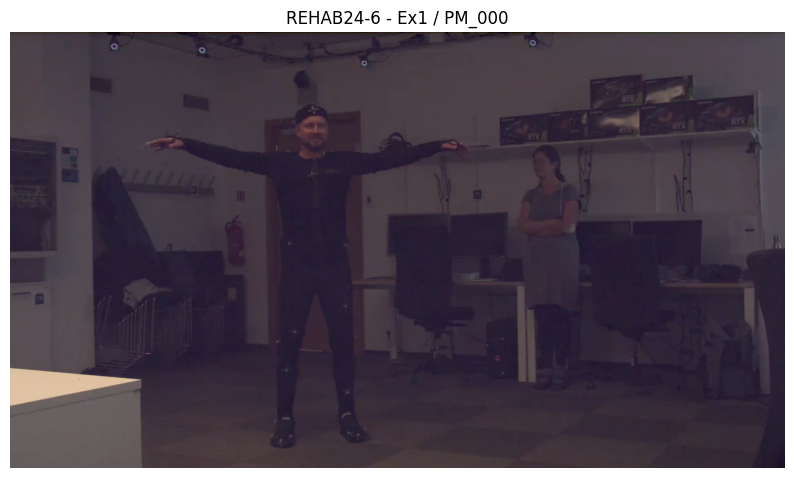

In [ ]:
# Exibe o primeiro quadro do vídeo para verificar visualmente sua leitura.

import matplotlib.pyplot as plt
import cv2

video = cv2.VideoCapture(VIDEO_LOCAL)

sucesso, frame = video.read()
video.release()

if sucesso:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("REHAB24-6 - Ex1 / PM_000")
    plt.show()
else:
    print("Não foi possível ler o primeiro quadro.")

Yolo

Foram testados dois modelos de detecção de objetos: YOLOv8 e YOLO-World. Após comparar os resultados, verificou-se que o YOLOv8 apresentou detecções mais consistentes e maior velocidade no processamento do vídeo. Por esse motivo, foi escolhido para o projeto como modelo principal para identificar pessoas e objetos presentes no ambiente.

In [ ]:
# Instalar o YOLO
# Carrega a versão nano, mais leve e adequada para nossos testes iniciais
modelo_yolo = YOLO("yolov8n.pt")

print("YOLOv8 carregado com sucesso!")

YOLOv8 carregado com sucesso!


Objeto: person | Confiança: 89.71%
Objeto: person | Confiança: 88.99%
Objeto: chair | Confiança: 54.34%
Objeto: chair | Confiança: 49.71%
Objeto: chair | Confiança: 36.20%
Objeto: dining table | Confiança: 32.34%


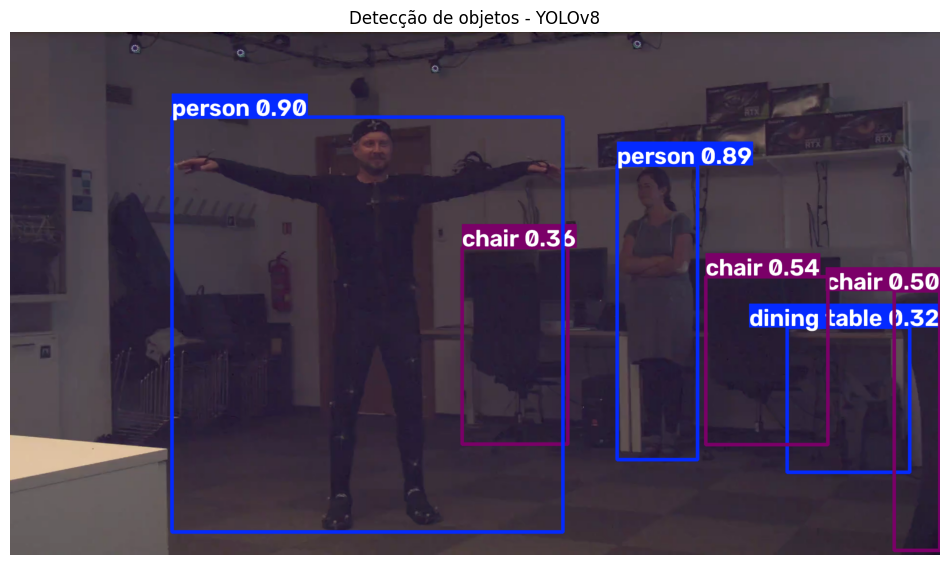

In [ ]:
# Executa o YOLOv8 no primeiro quadro e identifica os objetos detectados.

import cv2
import matplotlib.pyplot as plt
from collections import Counter

# Lê o primeiro quadro do vídeo
video = cv2.VideoCapture(VIDEO_LOCAL)
sucesso, frame = video.read()
video.release()

if not sucesso:
    raise RuntimeError("Não foi possível ler o quadro do vídeo.")

# Executa a detecção de objetos
resultados = modelo_yolo.predict(
    source=frame,
    conf=0.25,
    verbose=False
)

resultado = resultados[0]

# Exibe os objetos identificados e suas confianças
if len(resultado.boxes) > 0:
    for caixa in resultado.boxes:
        classe_id = int(caixa.cls[0])
        confianca = float(caixa.conf[0])
        nome = modelo_yolo.names[classe_id]

        print(f"Objeto: {nome} | Confiança: {confianca:.2%}")
else:
    print("Nenhum objeto foi detectado.")

# Exibe o quadro com as marcações do YOLO
imagem_detectada = resultado.plot()
imagem_rgb = cv2.cvtColor(imagem_detectada, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(imagem_rgb)
plt.axis("off")
plt.title("Detecção de objetos - YOLOv8")
plt.show()

In [ ]:
# Analisa o vídeo em intervalos de um segundo e contabiliza os objetos detectados.

import cv2
from collections import Counter

video = cv2.VideoCapture(VIDEO_LOCAL)

fps = video.get(cv2.CAP_PROP_FPS)
intervalo = int(fps)  # Um quadro por segundo

contagem_objetos = Counter()
total_quadros_analisados = 0

while True:
    sucesso, frame = video.read()

    if not sucesso:
        break

    numero_frame = int(video.get(cv2.CAP_PROP_POS_FRAMES))

    if numero_frame % intervalo == 0:
        resultados = modelo_yolo.predict(
            source=frame,
            conf=0.25,
            verbose=False
        )

        resultado = resultados[0]

        for caixa in resultado.boxes:
            classe_id = int(caixa.cls[0])
            nome = modelo_yolo.names[classe_id]

            contagem_objetos[nome] += 1

        total_quadros_analisados += 1

video.release()

print("Quadros analisados:", total_quadros_analisados)
print("\nDetecções acumuladas:")

for objeto, quantidade in contagem_objetos.most_common():
    print(f"{objeto}: {quantidade}")

Quadros analisados: 43

Detecções acumuladas:
chair: 100
person: 86
dining table: 3


In [ ]:
# Calcula a frequência de presença e a confiança média dos objetos no vídeo.

import cv2
from collections import defaultdict
import numpy as np

video = cv2.VideoCapture(VIDEO_LOCAL)

fps = video.get(cv2.CAP_PROP_FPS)
intervalo = int(fps)

estatisticas = defaultdict(lambda: {
    "quadros_presentes": 0,
    "deteccoes": 0,
    "confiancas": [],
    "maximo_simultaneo": 0
})

total_quadros = 0

while True:
    sucesso, frame = video.read()

    if not sucesso:
        break

    numero_frame = int(video.get(cv2.CAP_PROP_POS_FRAMES))

    if numero_frame % intervalo == 0:
        resultados = modelo_yolo.predict(
            source=frame,
            conf=0.25,
            verbose=False
        )

        resultado = resultados[0]
        objetos_no_quadro = defaultdict(list)

        for caixa in resultado.boxes:
            classe_id = int(caixa.cls[0])
            nome = modelo_yolo.names[classe_id]
            confianca = float(caixa.conf[0])

            objetos_no_quadro[nome].append(confianca)

        for nome, confiancas in objetos_no_quadro.items():
            estatisticas[nome]["quadros_presentes"] += 1
            estatisticas[nome]["deteccoes"] += len(confiancas)
            estatisticas[nome]["confiancas"].extend(confiancas)

            estatisticas[nome]["maximo_simultaneo"] = max(
                estatisticas[nome]["maximo_simultaneo"],
                len(confiancas)
            )

        total_quadros += 1

video.release()

print(f"Total de quadros analisados: {total_quadros}\n")

for objeto, dados in estatisticas.items():
    percentual = dados["quadros_presentes"] / total_quadros * 100
    confianca_media = np.mean(dados["confiancas"]) * 100

    print(f"Objeto: {objeto}")
    print(f"Presença nos quadros: {percentual:.1f}%")
    print(f"Total de detecções: {dados['deteccoes']}")
    print(f"Máximo simultâneo: {dados['maximo_simultaneo']}")
    print(f"Confiança média: {confianca_media:.2f}%")
    print("-" * 35)

Total de quadros analisados: 43

Objeto: person
Presença nos quadros: 100.0%
Total de detecções: 86
Máximo simultâneo: 2
Confiança média: 89.21%
-----------------------------------
Objeto: chair
Presença nos quadros: 100.0%
Total de detecções: 100
Máximo simultâneo: 3
Confiança média: 37.28%
-----------------------------------
Objeto: dining table
Presença nos quadros: 7.0%
Total de detecções: 3
Máximo simultâneo: 1
Confiança média: 29.43%
-----------------------------------


Yolo Pose

Durante a implementação, o MediaPipe apresentou erros de compatibilidade com as bibliotecas instaladas no Google Colab. Por isso, optou-se por substituí-lo pelo YOLOv8-Pose, evitando novos conflitos e aproveitando uma ferramenta já utilizada no projeto para identificar os pontos corporais e analisar os movimentos.

In [ ]:
# Carrega o modelo YOLOv8 especializado em identificação de pontos corporais.

from ultralytics import YOLO

modelo_pose = YOLO("yolov8n-pose.pt")

print("YOLOv8-Pose carregado com sucesso!")

YOLOv8-Pose carregado com sucesso!


Pessoas identificadas: 2


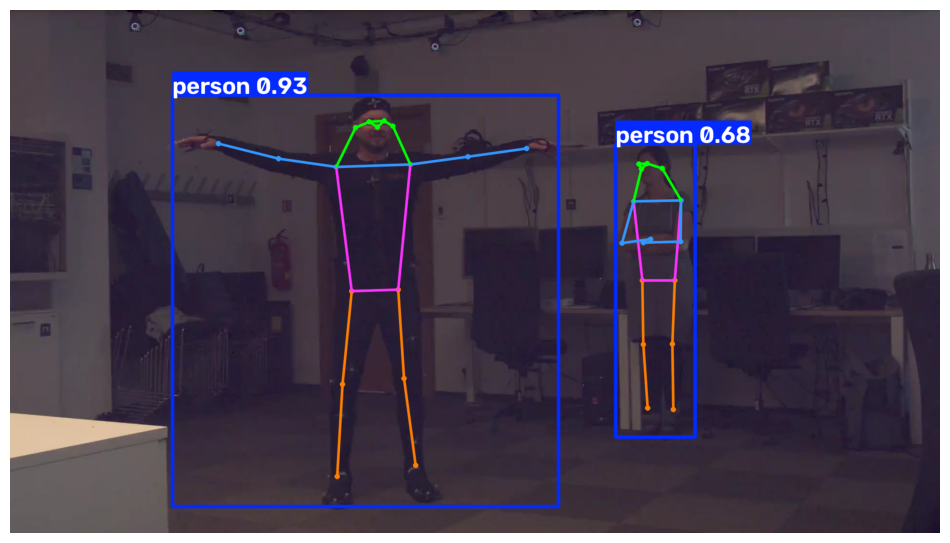

In [ ]:
# Executa o YOLOv8-Pose no primeiro quadro e exibe os pontos corporais identificados.
import cv2
import matplotlib.pyplot as plt

video = cv2.VideoCapture(VIDEO_LOCAL)
sucesso, frame = video.read()
video.release()

if not sucesso:
    raise RuntimeError("Não foi possível ler o vídeo.")

resultados_pose = modelo_pose.predict(source=frame, conf=0.25, verbose=False)

resultado_pose = resultados_pose[0]

print("Pessoas identificadas:", len(resultado_pose.keypoints))

imagem_anotada = resultado_pose.plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(imagem_anotada, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
# Extrai as coordenadas e os níveis de confiança dos pontos corporais ao longo do vídeo.
import cv2
import pandas as pd

video = cv2.VideoCapture(VIDEO_LOCAL)

fps = video.get(cv2.CAP_PROP_FPS)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

dados_pose = []
indice_frame = 0

while True:
    sucesso, frame = video.read()

    if not sucesso:
        break

    if indice_frame % 3 == 0:
        resultado = modelo_pose.predict(
            source=frame,
            conf=0.25,
            verbose=False
        )[0]

        if resultado.keypoints is not None:
            pontos = resultado.keypoints.data.cpu().numpy()

            for pessoa_id, pontos_pessoa in enumerate(pontos):
                for ponto_id, (x, y, confianca) in enumerate(pontos_pessoa):
                    dados_pose.append({
                        "frame": indice_frame,
                        "tempo_segundos": indice_frame / fps,
                        "pessoa": pessoa_id,
                        "ponto_corporal": ponto_id,
                        "x": float(x),
                        "y": float(y),
                        "confianca": float(confianca)
                    })

    indice_frame += 1

video.release()

df_pose = pd.DataFrame(dados_pose)
df_pose.to_csv("/content/pontos_corporais.csv", index=False)

print("Extração concluída!")
print("Frames analisados:", len(range(0, total_frames, 3)))
print("Registros extraídos:", len(df_pose))
print("Arquivo salvo: /content/pontos_corporais.csv")

Extração concluída!
Frames analisados: 435
Registros extraídos: 14790
Arquivo salvo: /content/pontos_corporais.csv


In [ ]:
# Calcula a confiança média e a quantidade de pontos detectados por pessoa.
import pandas as pd

resumo_pose = df_pose.groupby("pessoa").agg(
    total_registros=("confianca", "count"),
    confianca_media=("confianca", "mean"),
    confianca_minima=("confianca", "min"),
    pontos_baixa_confianca=("confianca", lambda x: (x < 0.5).sum())
).round(3)

display(resumo_pose)

,total_registros,confianca_media,confianca_minima,pontos_baixa_confianca
pessoa,,,,
0,7395,0.957,0.643,0
1,7395,0.911,0.166,159


In [ ]:
# Reprocessa o vídeo com rastreamento individual e registra os pontos corporais de cada pessoa.
import cv2
import pandas as pd

video = cv2.VideoCapture(VIDEO_LOCAL)

fps = video.get(cv2.CAP_PROP_FPS)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

dados_tracking = []
indice_frame = 0

while True:
    sucesso, frame = video.read()

    if not sucesso:
        break

    if indice_frame % 3 == 0:
        resultado = modelo_pose.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=0.25,
            verbose=False
        )[0]

        if resultado.keypoints is not None and resultado.boxes.id is not None:
            pontos = resultado.keypoints.data.cpu().numpy()
            ids = resultado.boxes.id.cpu().numpy().astype(int)

            for pessoa_id, pontos_pessoa in zip(ids, pontos):
                for ponto_id, (x, y, confianca) in enumerate(pontos_pessoa):
                    dados_tracking.append({
                        "frame": indice_frame,
                        "tempo_segundos": indice_frame / fps,
                        "pessoa_id": pessoa_id,
                        "ponto_corporal": ponto_id,
                        "x": float(x),
                        "y": float(y),
                        "confianca": float(confianca)
                    })

    indice_frame += 1

video.release()

df_tracking = pd.DataFrame(dados_tracking)
df_tracking.to_csv("/content/pontos_corporais_tracking.csv", index=False)

print("Rastreamento concluído!")
print("Frames analisados:", len(range(0, total_frames, 3)))
print("Pessoas rastreadas:", df_tracking["pessoa_id"].nunique())
print("Registros extraídos:", len(df_tracking))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 344ms
Prepared 1 package in 95ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Rastreamento concluído!
Frames analisados: 435
Pessoas rastreadas: 2
Registros extraídos: 14790


In [ ]:
# Verifica em quantos quadros cada identificador de pessoa foi rastreado.
resumo_tracking = df_tracking.groupby("pessoa_id").agg(
    quadros_detectados=("frame", "nunique"),
    primeiro_frame=("frame", "min"),
    ultimo_frame=("frame", "max"),
    confianca_media=("confianca", "mean")
).round(3)

display(resumo_tracking)

,quadros_detectados,primeiro_frame,ultimo_frame,confianca_media
pessoa_id,,,,
1,435,0,1302,0.958
2,435,0,1302,0.911


In [ ]:
# Calcula os ângulos dos membros superiores, inferiores e a inclinação do tronco.
import numpy as np
import pandas as pd

def calcular_angulo(a, b, c):
    vetor1 = np.array(a) - np.array(b)
    vetor2 = np.array(c) - np.array(b)

    norma1 = np.linalg.norm(vetor1)
    norma2 = np.linalg.norm(vetor2)

    if norma1 == 0 or norma2 == 0:
        return np.nan

    cos_angulo = np.dot(vetor1, vetor2) / (norma1 * norma2)
    cos_angulo = np.clip(cos_angulo, -1.0, 1.0)

    return np.degrees(np.arccos(cos_angulo))


def calcular_inclinacao_tronco(ombros, quadris):
    vetor = np.array(ombros) - np.array(quadris)

    if np.linalg.norm(vetor) == 0:
        return np.nan

    # Ângulo em relação à vertical da imagem.
    return np.degrees(
        np.arctan2(abs(vetor[0]), abs(vetor[1]))
    )


dados_angulos = []

for (frame, pessoa_id), grupo in df_tracking.groupby(["frame", "pessoa_id"]):

    pontos = {
        int(linha.ponto_corporal): (
            linha.x,
            linha.y,
            linha.confianca
        )
        for linha in grupo.itertuples()
    }

    registro = {
        "frame": frame,
        "tempo_segundos": grupo["tempo_segundos"].iloc[0],
        "pessoa_id": pessoa_id
    }

    articulacoes = {
        "braco_esquerdo": (5, 7, 9),
        "braco_direito": (6, 8, 10),
        "perna_esquerda": (11, 13, 15),
        "perna_direita": (12, 14, 16)
    }

    for nome, (p1, p2, p3) in articulacoes.items():

        ids = [p1, p2, p3]

        if all(i in pontos for i in ids):
            confiancas = [pontos[i][2] for i in ids]

            if min(confiancas) >= 0.5:
                registro[nome] = calcular_angulo(
                    pontos[p1][:2],
                    pontos[p2][:2],
                    pontos[p3][:2]
                )
            else:
                registro[nome] = np.nan
        else:
            registro[nome] = np.nan

    # Calcula a inclinação do tronco usando ombros e quadris.
    ids_tronco = [5, 6, 11, 12]

    if all(i in pontos for i in ids_tronco):
        confiancas = [pontos[i][2] for i in ids_tronco]

        if min(confiancas) >= 0.5:
            centro_ombros = np.mean(
                [pontos[5][:2], pontos[6][:2]], axis=0
            )

            centro_quadris = np.mean(
                [pontos[11][:2], pontos[12][:2]], axis=0
            )

            registro["inclinacao_tronco"] = calcular_inclinacao_tronco(
                centro_ombros,
                centro_quadris
            )
        else:
            registro["inclinacao_tronco"] = np.nan
    else:
        registro["inclinacao_tronco"] = np.nan

    dados_angulos.append(registro)


df_angulos = pd.DataFrame(dados_angulos)

df_angulos.to_csv("/content/angulos_articulares.csv", index=False)

print("Cálculo dos ângulos concluído!")
print("Registros:", len(df_angulos))
print("Pessoas analisadas:", df_angulos["pessoa_id"].nunique())
print("Arquivo salvo: /content/angulos_articulares.csv")

display(df_angulos.head(10))

Cálculo dos ângulos concluído!
Registros: 870
Pessoas analisadas: 2
Arquivo salvo: /content/angulos_articulares.csv


,frame,tempo_segundos,pessoa_id,braco_esquerdo,braco_direito,perna_esquerda,perna_direita,inclinacao_tronco
0,0,0.0,1,179.847437,174.449107,176.105789,177.692483,0.846258
1,0,0.0,2,92.229782,67.035280,177.267275,177.187888,0.768973
2,3,0.1,1,177.228622,173.828374,176.373843,177.616555,0.839720
3,3,0.1,2,91.497406,69.981803,176.791547,176.576524,0.554014
4,6,0.2,1,178.021859,174.185320,176.076703,177.410916,0.888586
5,6,0.2,2,93.949547,70.707965,177.741997,176.900937,0.639732
6,9,0.3,1,178.930141,174.294466,176.533866,178.362929,0.577143
7,9,0.3,2,93.501367,72.889662,176.930528,176.333456,0.449645
8,12,0.4,1,178.701057,174.857615,176.297433,178.064456,0.506730
9,12,0.4,2,93.594394,84.781516,178.439328,172.132124,0.651378


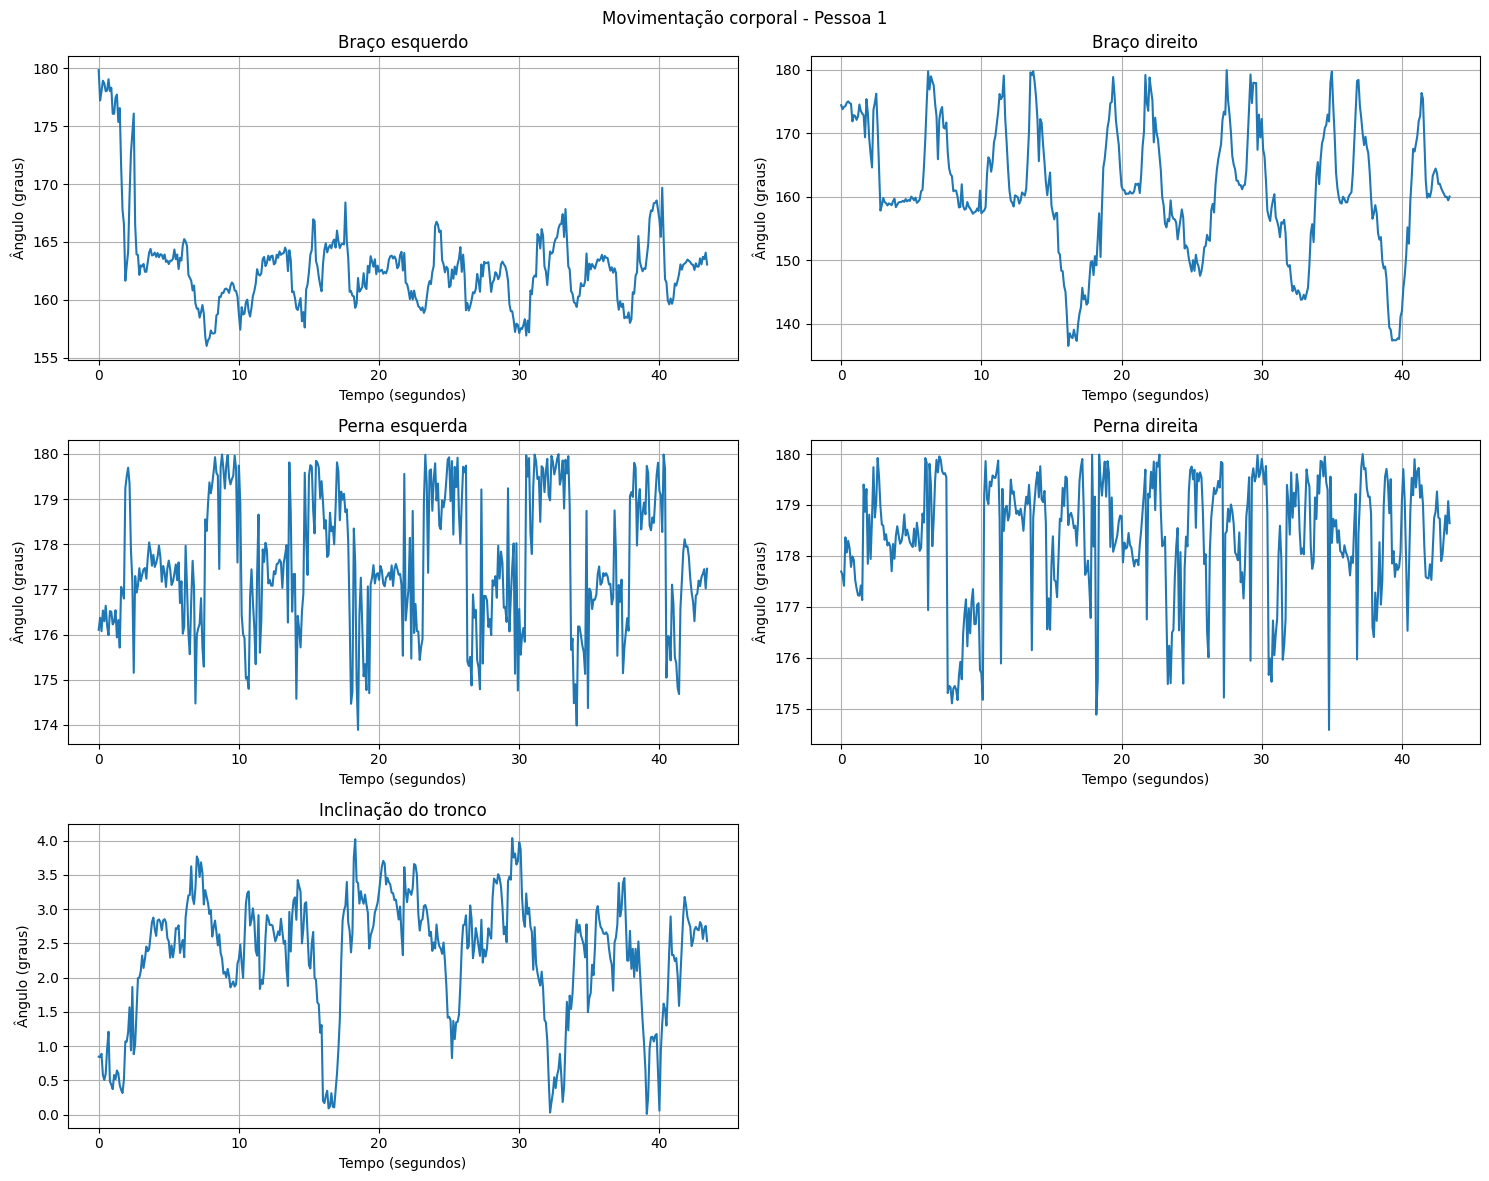

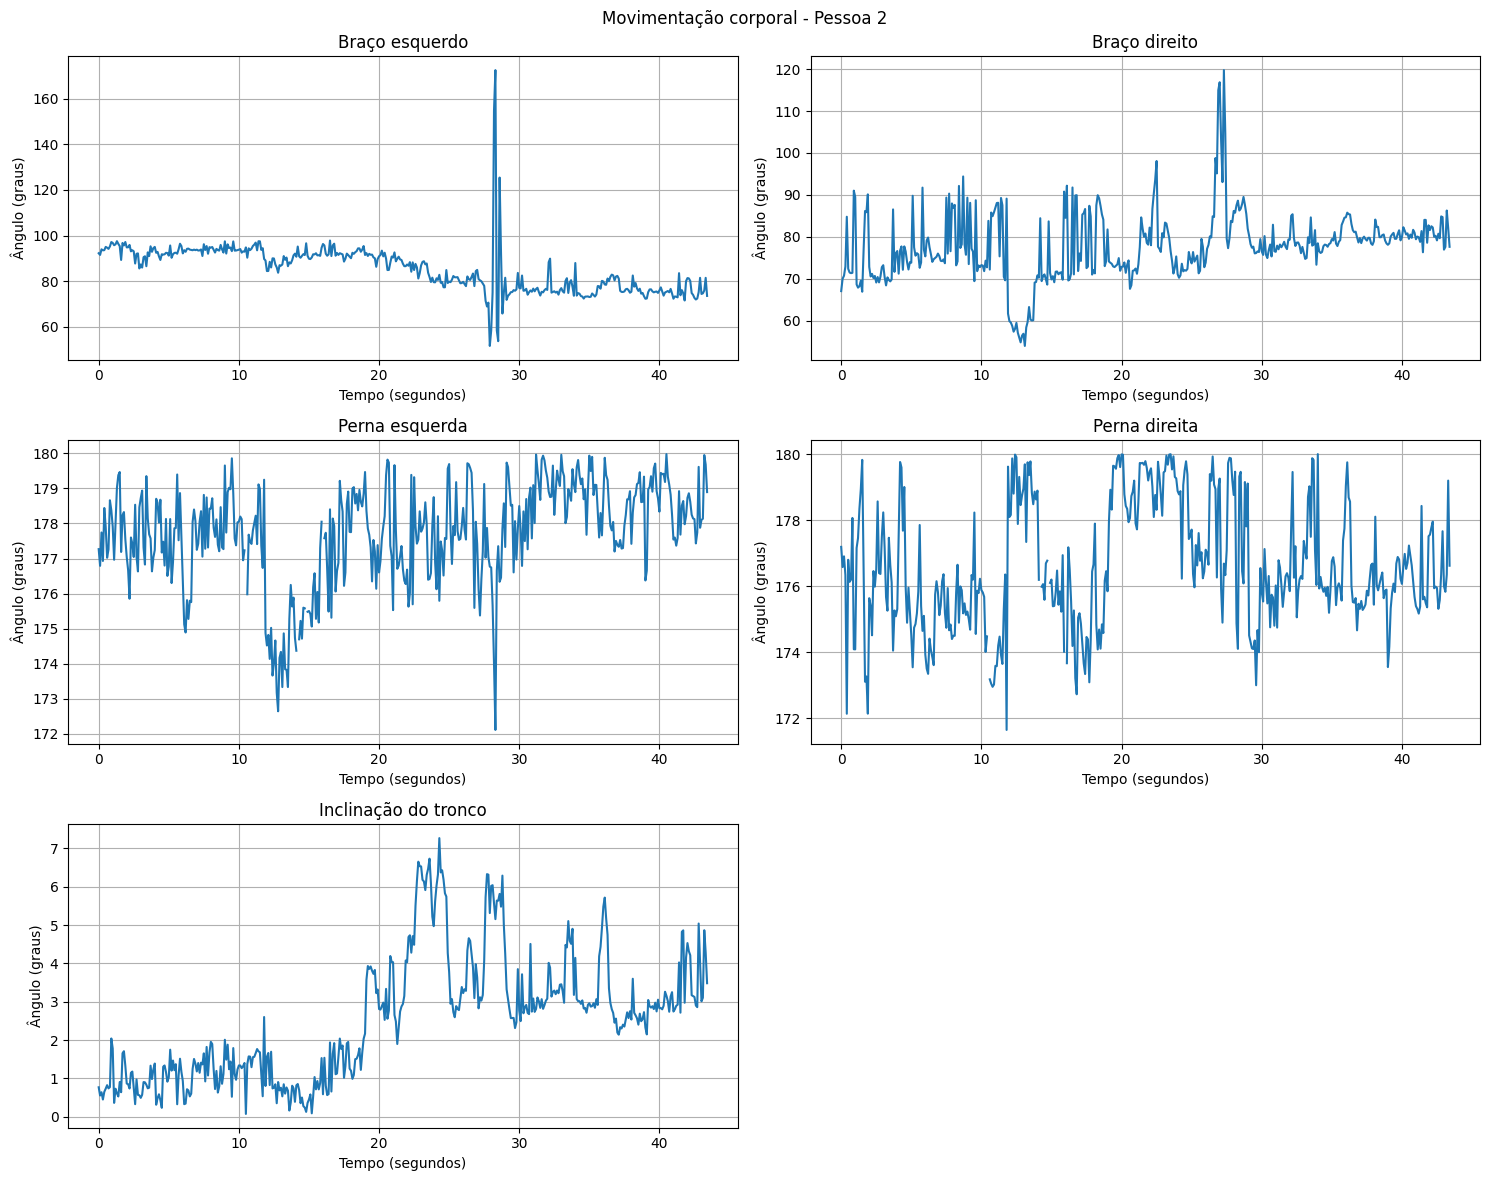

In [ ]:
# Gera gráficos da evolução dos ângulos articulares para cada pessoa.
import matplotlib.pyplot as plt

medidas = [
    "braco_esquerdo",
    "braco_direito",
    "perna_esquerda",
    "perna_direita",
    "inclinacao_tronco"
]

nomes = {
    "braco_esquerdo": "Braço esquerdo",
    "braco_direito": "Braço direito",
    "perna_esquerda": "Perna esquerda",
    "perna_direita": "Perna direita",
    "inclinacao_tronco": "Inclinação do tronco"
}

for pessoa in sorted(df_angulos["pessoa_id"].unique()):

    dados = df_angulos[df_angulos["pessoa_id"] == pessoa]

    fig, axes = plt.subplots(3, 2, figsize=(15, 12))
    axes = axes.flatten()

    for i, medida in enumerate(medidas):
        axes[i].plot(
            dados["tempo_segundos"],
            dados[medida]
        )
        axes[i].set_title(nomes[medida])
        axes[i].set_xlabel("Tempo (segundos)")
        axes[i].set_ylabel("Ângulo (graus)")
        axes[i].grid(True)

    axes[5].axis("off")

    fig.suptitle(f"Movimentação corporal - Pessoa {pessoa}")
    plt.tight_layout()
    plt.show()

In [ ]:
# Gera estatísticas descritivas dos ângulos e da inclinação do tronco por pessoa.
medidas = [
    "braco_esquerdo",
    "braco_direito",
    "perna_esquerda",
    "perna_direita",
    "inclinacao_tronco"
]

resumo_angulos = df_angulos.groupby("pessoa_id")[medidas].agg(
    ["mean", "std", "min", "max"]
).round(2)

display(resumo_angulos)

braco_esquerdo                        braco_direito                 \
                    mean    std     min     max          mean    std     min   
pessoa_id                                                                      
1                 162.93   3.91  156.01  179.85        161.32  10.12  136.53   
2                  85.43  10.23   51.55  172.60         77.75   8.10   53.96   

                  perna_esquerda                       perna_direita        \
              max           mean   std     min     max          mean   std   
pessoa_id                                                                    
1          179.97         177.57  1.47  173.89  180.00        178.37  1.17   
2          119.76         177.72  1.43  172.12  179.97        176.60  1.87   

                         inclinacao_tronco                    
              min    max              mean   std   min   max  
pessoa_id                                                     
1          174.58  180.0              2.33  0.91  0.01  4.04  
2          171.64  180.0              2.54  1.62  0.07  7.27

In [ ]:
# Baixa as anotações do REHAB24-6 e apresenta sua estrutura.
import requests
import pandas as pd

arquivos = {
    "Segmentation.csv": "https://zenodo.org/api/records/13305826/files/Segmentation.csv/content",
    "Segmentation.txt": "https://zenodo.org/api/records/13305826/files/Segmentation.txt/content"
}

for nome, url in arquivos.items():
    resposta = requests.get(url)
    resposta.raise_for_status()

    with open(f"/content/{nome}", "wb") as arquivo:
        arquivo.write(resposta.content)

df_segmentacao = pd.read_csv("/content/Segmentation.csv")

print("Dimensões:", df_segmentacao.shape)
print("\nColunas disponíveis:")
print(df_segmentacao.columns.tolist())

print("\nPrimeiros registros:")
display(df_segmentacao.head())

print("\nDescrição das anotações:")
with open("/content/Segmentation.txt", "r", encoding="utf-8") as arquivo:
    print(arquivo.read())

Dimensões: (1072, 1)

Colunas disponíveis:
['video_id;repetition_number;exercise_id;person_id;first_frame;last_frame;cam17_orientation;mocap_erroneous;exercise_subtype;lights_on;extra_person_in_cam17;extra_person_in_cam18;correctness']

Primeiros registros:


,video_id;repetition_number;exercise_id;person_id;first_frame;last_frame;cam17_orientation;mocap_erroneous;exercise_subtype;lights_on;extra_person_in_cam17;extra_person_in_cam18;correctness
0,PM_000;1;1;1;180;377;front;0;right arm;0;3;0;1
1,PM_000;2;1;1;378;620;front;0;right arm;0;3;0;1
2,PM_000;3;1;1;621;865;front;0;right arm;0;3;0;1
3,PM_000;4;1;1;866;1085;front;0;right arm;0;3;3;1
4,PM_000;5;1;1;1086;1265;front;0;right arm;0;3;3;1



Descrição das anotações:
Semantics of csv file columns and values
video_id -- id of the video file
repetition_number -- number of repetition within given video
exercise_id -- id of the exercise; description of exercises is provided on the main dataset page on Zenodo
person_id -- id of exercising person
first_frame -- number of the first frame of the repetition
last_frame -- number of the last frame of the repetition
cam17_orientation -- orientation of exercising person towards camera17, possible values are 'front', 'half-profile' and 'profile'; as camera18 was placed orthogonally to camera17, this also implies orientation of the person towards camera18
  cam17 orientation -> cam18 orientation
  front -> side
  half-profile -> half-profile
  side -> front
mocap_erroneous -- indication whether there is an error in mocap data (some markers not correctly detected)
exercise_subtype -- for some exercises, we distinguish between right- and left-sided execution of the exercise
lights_on -- in

In [ ]:
# Reabre o arquivo de anotações utilizando o separador correto.
df_segmentacao = pd.read_csv("/content/Segmentation.csv", sep=";")

print("Dimensões:", df_segmentacao.shape)
print("\nColunas:", df_segmentacao.columns.tolist())

print("\nDistribuição das classificações:")
print(df_segmentacao["correctness"].value_counts())

print("\nExercícios disponíveis:")
print(df_segmentacao.groupby("exercise_id")["video_id"].nunique())

print("\nPrimeiros registros:")
display(df_segmentacao.head())

Dimensões: (1072, 13)

Colunas: ['video_id', 'repetition_number', 'exercise_id', 'person_id', 'first_frame', 'last_frame', 'cam17_orientation', 'mocap_erroneous', 'exercise_subtype', 'lights_on', 'extra_person_in_cam17', 'extra_person_in_cam18', 'correctness']

Distribuição das classificações:
correctness
1    568
0    504
Name: count, dtype: int64

Exercícios disponíveis:
exercise_id
1    13
2    12
3    10
4    12
5     9
6     9
Name: video_id, dtype: int64

Primeiros registros:


,video_id,repetition_number,exercise_id,person_id,first_frame,last_frame,cam17_orientation,mocap_erroneous,exercise_subtype,lights_on,extra_person_in_cam17,extra_person_in_cam18,correctness
0,PM_000,1,1,1,180,377,front,0,right arm,0,3,0,1
1,PM_000,2,1,1,378,620,front,0,right arm,0,3,0,1
2,PM_000,3,1,1,621,865,front,0,right arm,0,3,0,1
3,PM_000,4,1,1,866,1085,front,0,right arm,0,3,3,1
4,PM_000,5,1,1,1086,1265,front,0,right arm,0,3,3,1


In [ ]:
# Relaciona cada repetição anotada do vídeo PM_000 aos ângulos das duas pessoas rastreadas.
anotacoes_video = df_segmentacao[
    df_segmentacao["video_id"] == "PM_000"
].copy()

resultados_repeticoes = []

for _, repeticao in anotacoes_video.iterrows():
    inicio = repeticao["first_frame"]
    fim = repeticao["last_frame"]

    trecho = df_angulos[
        (df_angulos["frame"] >= inicio) &
        (df_angulos["frame"] <= fim)
    ]

    for pessoa in sorted(trecho["pessoa_id"].unique()):
        dados = trecho[trecho["pessoa_id"] == pessoa]

        resultados_repeticoes.append({
            "repeticao": repeticao["repetition_number"],
            "classificacao": repeticao["correctness"],
            "subtipo": repeticao["exercise_subtype"],
            "pessoa_dataset": repeticao["person_id"],
            "pessoa_tracking": pessoa,
            "frames": len(dados),
            "braco_esquerdo_medio": dados["braco_esquerdo"].mean(),
            "braco_direito_medio": dados["braco_direito"].mean(),
            "perna_esquerda_media": dados["perna_esquerda"].mean(),
            "perna_direita_media": dados["perna_direita"].mean(),
            "tronco_medio": dados["inclinacao_tronco"].mean()
        })

df_repeticoes = pd.DataFrame(resultados_repeticoes)

display(df_repeticoes.round(2))


,repeticao,classificacao,subtipo,pessoa_dataset,pessoa_tracking,frames,braco_esquerdo_medio,braco_direito_medio,perna_esquerda_media,perna_direita_media,tronco_medio
0,1,1,right arm,1,1,66,160.56,165.61,177.63,177.98,2.68
1,1,1,right arm,1,2,66,93.32,77.12,177.35,175.36,1.24
2,2,1,right arm,1,1,81,162.71,158.07,177.60,178.56,2.42
3,2,1,right arm,1,2,81,91.22,73.50,176.69,176.74,1.46
4,3,1,right arm,1,1,82,162.10,161.19,177.64,178.34,2.67
5,3,1,right arm,1,2,82,83.84,81.42,177.38,178.37,4.59
6,4,1,right arm,1,1,73,162.09,160.21,177.75,178.49,2.20
7,4,1,right arm,1,2,73,76.41,78.67,178.80,176.38,3.35
8,5,1,right arm,1,1,60,162.66,158.15,177.66,178.44,2.04
9,5,1,right arm,1,2,60,76.69,80.50,178.46,176.12,2.99


In [ ]:
# Calcula o ângulo de elevação do braço direito em relação ao tronco.
dados_ombro = []

for (frame, pessoa_id), grupo in df_tracking.groupby(["frame", "pessoa_id"]):
    pontos = {
        int(linha.ponto_corporal): (linha.x, linha.y, linha.confianca)
        for linha in grupo.itertuples()
    }

    registro = {
        "frame": frame,
        "pessoa_id": pessoa_id,
        "elevacao_braco_direito": np.nan
    }

    # COCO: quadril direito = 12, ombro direito = 6, cotovelo direito = 8.
    ids = [12, 6, 8]

    if all(i in pontos for i in ids):
        if min(pontos[i][2] for i in ids) >= 0.5:
            registro["elevacao_braco_direito"] = calcular_angulo(
                pontos[12][:2],
                pontos[6][:2],
                pontos[8][:2]
            )

    dados_ombro.append(registro)

df_ombro = pd.DataFrame(dados_ombro)

df_angulos = df_angulos.merge(
    df_ombro,
    on=["frame", "pessoa_id"],
    how="left"
)

print("Cálculo concluído!")
display(df_angulos.head())

Cálculo concluído!


,frame,tempo_segundos,pessoa_id,braco_esquerdo,braco_direito,perna_esquerda,perna_direita,inclinacao_tronco,elevacao_braco_direito
0,0,0.0,1,179.847437,174.449107,176.105789,177.692483,0.846258,105.409738
1,0,0.0,2,92.229782,67.035280,177.267275,177.187888,0.768973,21.546570
2,3,0.1,1,177.228622,173.828374,176.373843,177.616555,0.839720,104.799564
3,3,0.1,2,91.497406,69.981803,176.791547,176.576524,0.554014,20.543639
4,6,0.2,1,178.021859,174.185320,176.076703,177.410916,0.888586,104.984961


In [ ]:
# Calcula a elevação média do braço direito em cada repetição e pessoa rastreada.
resultados_repeticoes = []

for _, repeticao in anotacoes_video.iterrows():
    inicio = repeticao["first_frame"]
    fim = repeticao["last_frame"]

    trecho = df_angulos[
        (df_angulos["frame"] >= inicio) &
        (df_angulos["frame"] <= fim)
    ]

    for pessoa in sorted(trecho["pessoa_id"].unique()):
        dados = trecho[trecho["pessoa_id"] == pessoa]

        resultados_repeticoes.append({
            "repeticao": repeticao["repetition_number"],
            "classificacao": repeticao["correctness"],
            "subtipo": repeticao["exercise_subtype"],
            "pessoa_tracking": pessoa,
            "frames": len(dados),
            "elevacao_media": dados["elevacao_braco_direito"].mean(),
            "elevacao_minima": dados["elevacao_braco_direito"].min(),
            "elevacao_maxima": dados["elevacao_braco_direito"].max(),
            "elevacao_desvio": dados["elevacao_braco_direito"].std()
        })

df_repeticoes = pd.DataFrame(resultados_repeticoes)

display(df_repeticoes.round(2))

,repeticao,classificacao,subtipo,pessoa_tracking,frames,elevacao_media,elevacao_minima,elevacao_maxima,elevacao_desvio
0,1,1,right arm,1,66,83.55,19.76,130.81,40.96
1,1,1,right arm,2,66,17.36,12.97,21.54,2.30
2,2,1,right arm,1,81,90.88,19.77,168.87,57.99
3,2,1,right arm,2,81,18.10,10.93,22.07,2.83
4,3,1,right arm,1,82,86.01,19.10,170.74,55.66
5,3,1,right arm,2,82,13.08,3.34,20.81,4.23
6,4,1,right arm,1,73,94.08,19.97,166.73,52.83
7,4,1,right arm,2,73,8.94,3.41,12.99,1.87
8,5,1,right arm,1,60,94.28,19.46,164.03,53.92
9,5,1,right arm,2,60,7.26,3.66,10.69,1.17


In [ ]:
# Verifica a quantidade de repetições corretas e incorretas no vídeo.
print("Total de repetições:", len(anotacoes_video))

print("\nDistribuição das classificações:")
display(
    anotacoes_video["correctness"]
    .value_counts()
    .rename(index={1: "Corretas", 0: "Incorretas"})
)

print("\nDetalhamento das repetições:")
display(
    anotacoes_video[
        ["repetition_number", "exercise_id", "exercise_subtype",
         "first_frame", "last_frame", "correctness"]
    ]
)

Total de repetições: 5

Distribuição das classificações:


,count
correctness,
Corretas,5



Detalhamento das repetições:


,repetition_number,exercise_id,exercise_subtype,first_frame,last_frame,correctness
0,1,1,right arm,180,377,1
1,2,1,right arm,378,620,1
2,3,1,right arm,621,865,1
3,4,1,right arm,866,1085,1
4,5,1,right arm,1086,1265,1


In [ ]:
# Identifica vídeos do exercício 1 que possuem repetições corretas e incorretas.
candidatos = df_segmentacao[
    (df_segmentacao["exercise_id"] == 1) &
    (df_segmentacao["exercise_subtype"] == "right arm")
].groupby("video_id").agg(
    total_repeticoes=("correctness", "size"),
    corretas=("correctness", lambda x: (x == 1).sum()),
    incorretas=("correctness", lambda x: (x == 0).sum()),
    orientacao=("cam17_orientation", "first"),
    pessoa_extra=("extra_person_in_cam17", "max"),
    erro_mocap=("mocap_erroneous", "max")
).reset_index()

candidatos = candidatos[
    candidatos["incorretas"] > 0
].sort_values(
    ["corretas", "incorretas"],
    ascending=False
)

display(candidatos)

,video_id,total_repeticoes,corretas,incorretas,orientacao,pessoa_extra,erro_mocap
11,PM_114,22,11,11,front,2,0
7,PM_032,21,10,11,front,2,0
8,PM_039,21,10,11,front,2,0
10,PM_109,20,10,10,front,2,0
12,PM_122,20,10,10,front,2,0
1,PM_001,10,5,5,front,1,0
3,PM_012,10,5,5,front,2,0
4,PM_016,10,5,5,half-profile,2,0
5,PM_023,10,5,5,front,2,0
6,PM_024,10,5,5,half-profile,3,0


In [ ]:
# Localiza o vídeo PM_001 da câmera 17 no conjunto REHAB24-6.
arquivos_pm001 = [
    arquivo for arquivo in zip_fs.glob("**/*PM_001*Camera17*.mp4")
]

print("Arquivos encontrados:", arquivos_pm001)

Arquivos encontrados: ['Ex1/PM_001-Camera17-30fps.mp4']


In [ ]:
# Extrai o vídeo PM_001 da câmera 17 para análise.
import os

CAMINHO_VIDEO_PM001 = "/content/video_PM_001.mp4"

with zip_fs.open(arquivos_pm001[0], "rb") as origem:
    with open(CAMINHO_VIDEO_PM001, "wb") as destino:
        destino.write(origem.read())

print("Vídeo extraído:", CAMINHO_VIDEO_PM001)
print("Tamanho:", round(os.path.getsize(CAMINHO_VIDEO_PM001) / (1024 * 1024), 2), "MB")


Vídeo extraído: /content/video_PM_001.mp4
Tamanho: 25.25 MB


In [ ]:
# Verifica as propriedades do vídeo PM_001.
import cv2

video_pm001 = cv2.VideoCapture(CAMINHO_VIDEO_PM001)

fps_pm001 = video_pm001.get(cv2.CAP_PROP_FPS)
total_frames_pm001 = int(video_pm001.get(cv2.CAP_PROP_FRAME_COUNT))
largura_pm001 = int(video_pm001.get(cv2.CAP_PROP_FRAME_WIDTH))
altura_pm001 = int(video_pm001.get(cv2.CAP_PROP_FRAME_HEIGHT))

video_pm001.release()

print("Resolução:", largura_pm001, "x", altura_pm001)
print("FPS:", fps_pm001)
print("Total de quadros:", total_frames_pm001)
print("Duração:", round(total_frames_pm001 / fps_pm001, 2), "segundos")

Resolução: 1920 x 1080
FPS: 30.0
Total de quadros: 3016
Duração: 100.53 segundos


In [ ]:
# Rastreia as pessoas e extrai os 17 pontos corporais ao longo do vídeo PM_001.
import cv2
import pandas as pd

video = cv2.VideoCapture(CAMINHO_VIDEO_PM001)
fps = video.get(cv2.CAP_PROP_FPS)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

dados_tracking_pm001 = []
indice_frame = 0

while True:
    sucesso, frame = video.read()
    if not sucesso:
        break

    if indice_frame % 3 == 0:
        resultado = modelo_pose.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=0.25,
            verbose=False
        )[0]

        if resultado.keypoints is not None and resultado.boxes.id is not None:
            pontos = resultado.keypoints.data.cpu().numpy()
            ids = resultado.boxes.id.cpu().numpy().astype(int)

            for pessoa_id, pontos_pessoa in zip(ids, pontos):
                for ponto_id, (x, y, confianca) in enumerate(pontos_pessoa):
                    dados_tracking_pm001.append({
                        "frame": indice_frame,
                        "tempo_segundos": indice_frame / fps,
                        "pessoa_id": pessoa_id,
                        "ponto_corporal": ponto_id,
                        "x": float(x),
                        "y": float(y),
                        "confianca": float(confianca)
                    })

    indice_frame += 1

video.release()

df_tracking_pm001 = pd.DataFrame(dados_tracking_pm001)
df_tracking_pm001.to_csv(
    "/content/pontos_corporais_PM001.csv",
    index=False
)

print("Rastreamento concluído!")
print("Frames analisados:", len(range(0, total_frames, 3)))
print("Pessoas rastreadas:", df_tracking_pm001["pessoa_id"].nunique())
print("Registros extraídos:", len(df_tracking_pm001))

Rastreamento concluído!
Frames analisados: 1006
Pessoas rastreadas: 6
Registros extraídos: 17527


In [ ]:
# Verifica a duração e a quantidade de detecções associadas a cada ID.
resumo_tracking_pm001 = df_tracking_pm001.groupby("pessoa_id").agg(
    quadros_detectados=("frame", "nunique"),
    primeiro_frame=("frame", "min"),
    ultimo_frame=("frame", "max"),
    confianca_media=("confianca", "mean")
).round(3)

display(resumo_tracking_pm001)

,quadros_detectados,primeiro_frame,ultimo_frame,confianca_media
pessoa_id,,,,
1,1006,0,3015,0.959
3,13,30,66,0.755
5,1,1152,1152,0.102
6,2,1365,1368,0.095
8,2,1407,1410,0.792
12,7,2973,3000,0.083


In [ ]:
# Calcula os ângulos corporais da pessoa principal rastreada no PM_001.
import numpy as np
import pandas as pd

df_pessoa_pm001 = df_tracking_pm001[
    df_tracking_pm001["pessoa_id"] == 1
].copy()

def calcular_angulo(a, b, c):
    vetor1 = np.array(a) - np.array(b)
    vetor2 = np.array(c) - np.array(b)
    norma1 = np.linalg.norm(vetor1)
    norma2 = np.linalg.norm(vetor2)

    if norma1 == 0 or norma2 == 0:
        return np.nan

    cos_angulo = np.dot(vetor1, vetor2) / (norma1 * norma2)
    return np.degrees(np.arccos(np.clip(cos_angulo, -1, 1)))

def calcular_inclinacao_tronco(ombros, quadris):
    vetor = np.array(ombros) - np.array(quadris)
    if np.linalg.norm(vetor) == 0:
        return np.nan
    return np.degrees(np.arctan2(abs(vetor[0]), abs(vetor[1])))

dados_angulos_pm001 = []

for (frame, pessoa_id), grupo in df_pessoa_pm001.groupby(["frame", "pessoa_id"]):
    pontos = {
        int(linha.ponto_corporal): (linha.x, linha.y, linha.confianca)
        for linha in grupo.itertuples()
    }

    registro = {
        "frame": frame,
        "tempo_segundos": grupo["tempo_segundos"].iloc[0],
        "pessoa_id": pessoa_id
    }

    articulacoes = {
        "braco_esquerdo": (5, 7, 9),
        "braco_direito": (6, 8, 10),
        "perna_esquerda": (11, 13, 15),
        "perna_direita": (12, 14, 16)
    }

    for nome, ids in articulacoes.items():
        if all(i in pontos for i in ids) and min(pontos[i][2] for i in ids) >= 0.5:
            registro[nome] = calcular_angulo(
                pontos[ids[0]][:2],
                pontos[ids[1]][:2],
                pontos[ids[2]][:2]
            )
        else:
            registro[nome] = np.nan

    ids_tronco = [5, 6, 11, 12]
    if all(i in pontos for i in ids_tronco) and min(pontos[i][2] for i in ids_tronco) >= 0.5:
        centro_ombros = np.mean([pontos[5][:2], pontos[6][:2]], axis=0)
        centro_quadris = np.mean([pontos[11][:2], pontos[12][:2]], axis=0)
        registro["inclinacao_tronco"] = calcular_inclinacao_tronco(
            centro_ombros, centro_quadris
        )
    else:
        registro["inclinacao_tronco"] = np.nan

    ids_ombro = [12, 6, 8]
    if all(i in pontos for i in ids_ombro) and min(pontos[i][2] for i in ids_ombro) >= 0.5:
        registro["elevacao_braco_direito"] = calcular_angulo(
            pontos[12][:2], pontos[6][:2], pontos[8][:2]
        )
    else:
        registro["elevacao_braco_direito"] = np.nan

    dados_angulos_pm001.append(registro)

df_angulos_pm001 = pd.DataFrame(dados_angulos_pm001)

df_angulos_pm001.to_csv(
    "/content/angulos_articulares_PM001.csv",
    index=False
)

print("Cálculo concluído!")
print("Registros:", len(df_angulos_pm001))
print("Ângulos calculados:", df_angulos_pm001.columns.tolist())

display(df_angulos_pm001.head())

Cálculo concluído!
Registros: 1006
Ângulos calculados: ['frame', 'tempo_segundos', 'pessoa_id', 'braco_esquerdo', 'braco_direito', 'perna_esquerda', 'perna_direita', 'inclinacao_tronco', 'elevacao_braco_direito']


,frame,tempo_segundos,pessoa_id,braco_esquerdo,braco_direito,perna_esquerda,perna_direita,inclinacao_tronco,elevacao_braco_direito
0,0,0.0,1,166.440377,173.139821,178.944369,179.847537,0.548645,98.434082
1,3,0.1,1,167.400808,172.512917,179.241838,179.226853,0.726168,98.184294
2,6,0.2,1,167.645579,173.297438,179.064667,179.503101,0.775521,98.587308
3,9,0.3,1,167.989355,173.503300,179.190084,179.995449,0.838945,98.817739
4,12,0.4,1,167.701745,173.509781,179.352518,179.727349,0.940457,98.413668


In [ ]:
# Associa os ângulos corporais às repetições anotadas do vídeo PM_001.
anotacoes_pm001 = df_segmentacao[
    (df_segmentacao["video_id"] == "PM_001") &
    (df_segmentacao["exercise_id"] == 1) &
    (df_segmentacao["exercise_subtype"] == "right arm")
].copy()

resultados_pm001 = []

for _, repeticao in anotacoes_pm001.iterrows():
    trecho = df_angulos_pm001[
        (df_angulos_pm001["frame"] >= repeticao["first_frame"]) &
        (df_angulos_pm001["frame"] <= repeticao["last_frame"])
    ]

    resultados_pm001.append({
        "repeticao": repeticao["repetition_number"],
        "classificacao": "Correta" if repeticao["correctness"] == 1 else "Incorreta",
        "quadros": len(trecho),
        "elevacao_braco_media": trecho["elevacao_braco_direito"].mean(),
        "elevacao_braco_min": trecho["elevacao_braco_direito"].min(),
        "elevacao_braco_max": trecho["elevacao_braco_direito"].max(),
        "elevacao_braco_desvio": trecho["elevacao_braco_direito"].std(),
        "braco_direito_medio": trecho["braco_direito"].mean(),
        "inclinacao_tronco_media": trecho["inclinacao_tronco"].mean(),
        "perna_esquerda_media": trecho["perna_esquerda"].mean(),
        "perna_direita_media": trecho["perna_direita"].mean()
    })

df_repeticoes_pm001 = pd.DataFrame(resultados_pm001)

display(df_repeticoes_pm001.round(2))

,repeticao,classificacao,quadros,elevacao_braco_media,elevacao_braco_min,elevacao_braco_max,elevacao_braco_desvio,braco_direito_medio,inclinacao_tronco_media,perna_esquerda_media,perna_direita_media
0,1,Correta,65,80.51,21.73,131.65,43.17,161.91,1.97,172.50,178.65
1,2,Correta,71,63.08,21.53,126.57,41.51,163.43,1.73,172.08,178.77
2,3,Correta,64,64.80,21.62,130.00,41.33,165.07,2.16,172.26,178.79
3,4,Correta,63,67.14,21.23,129.52,42.02,162.54,2.07,172.74,178.81
4,5,Correta,57,70.04,21.57,131.53,42.97,162.63,2.52,172.72,178.85
5,6,Incorreta,83,70.06,20.97,122.07,36.59,169.38,1.21,176.89,178.36
6,7,Incorreta,96,67.80,21.67,123.85,37.14,169.36,1.30,176.61,178.82
7,8,Incorreta,69,67.15,21.84,115.72,33.21,169.73,1.41,176.16,178.42
8,9,Incorreta,64,68.46,20.95,117.05,35.31,170.23,1.32,176.25,178.58
9,10,Incorreta,72,63.07,21.26,120.85,37.58,168.71,1.47,176.08,178.35


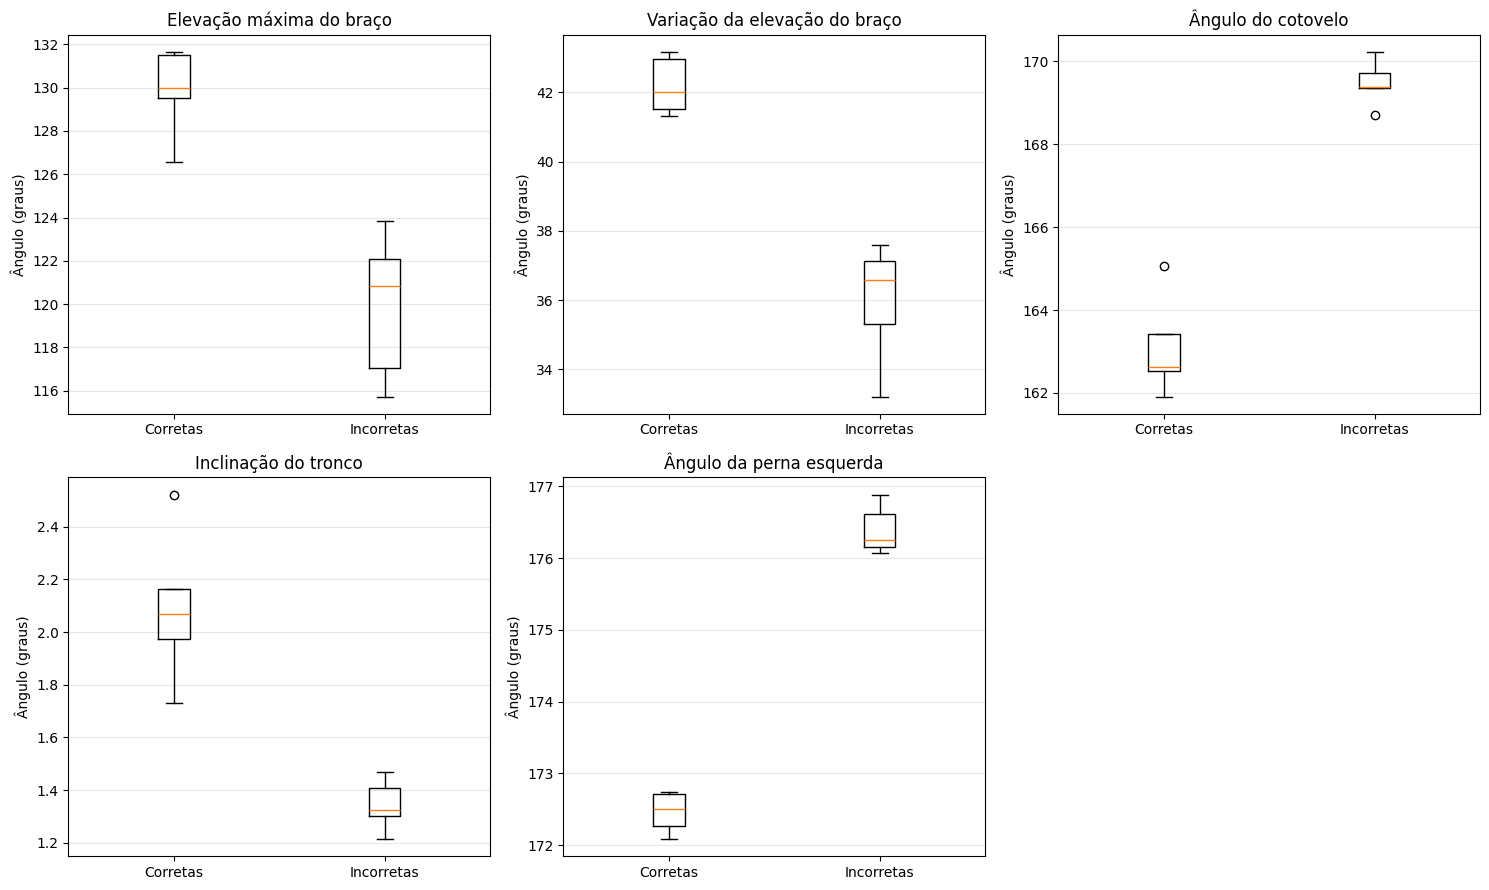

In [ ]:
# Compara visualmente os indicadores das repetições corretas e incorretas.
import matplotlib.pyplot as plt

indicadores = {
    "elevacao_braco_max": "Elevação máxima do braço",
    "elevacao_braco_desvio": "Variação da elevação do braço",
    "braco_direito_medio": "Ângulo do cotovelo",
    "inclinacao_tronco_media": "Inclinação do tronco",
    "perna_esquerda_media": "Ângulo da perna esquerda"
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (coluna, titulo) in enumerate(indicadores.items()):
    dados_corretos = df_repeticoes_pm001[
        df_repeticoes_pm001["classificacao"] == "Correta"
    ][coluna]

    dados_incorretos = df_repeticoes_pm001[
        df_repeticoes_pm001["classificacao"] == "Incorreta"
    ][coluna]

    axes[i].boxplot(
        [dados_corretos, dados_incorretos],
        tick_labels=["Corretas", "Incorretas"]
    )
    axes[i].set_title(titulo)
    axes[i].set_ylabel("Ângulo (graus)")
    axes[i].grid(axis="y", alpha=0.3)

axes[5].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Compara as médias, dispersões e intervalos dos indicadores por classificação.
colunas = [
    "elevacao_braco_max",
    "elevacao_braco_desvio",
    "braco_direito_medio",
    "inclinacao_tronco_media",
    "perna_esquerda_media",
    "perna_direita_media"
]

resumo_comparativo = df_repeticoes_pm001.groupby("classificacao")[colunas].agg(
    ["mean", "std", "min", "max"]
).round(2)

display(resumo_comparativo)

elevacao_braco_max                       elevacao_braco_desvio  \
                            mean   std     min     max                  mean   
classificacao                                                                  
Correta                   129.85  2.06  126.57  131.65                 42.20   
Incorreta                 119.91  3.42  115.72  123.85                 35.97   

                                  braco_direito_medio        ...  \
                std    min    max                mean   std  ...   
classificacao                                                ...   
Correta        0.83  41.33  43.17              163.11  1.22  ...   
Incorreta      1.76  33.21  37.58              169.48  0.55  ...   

              inclinacao_tronco_media       perna_esquerda_media        \
                                  min   max                 mean   std   
classificacao                                                            
Correta                          1.73  2.52               172.46  0.28   
Incorreta                        1.21  1.47               176.39  0.34   

                              perna_direita_media                        
                  min     max                mean   std     min     max  
classificacao                                                            
Correta        172.08  172.74              178.77  0.08  178.65  178.85  
Incorreta      176.08  176.89              178.51  0.20  178.35  178.82  

[2 rows x 24 columns]

In [ ]:
# Calcula o tamanho do efeito e o teste de Mann-Whitney entre as classificações.
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

indicadores = [
    "elevacao_braco_max",
    "elevacao_braco_desvio",
    "braco_direito_medio",
    "perna_esquerda_media",
    "inclinacao_tronco_media"
]

resultados_estatisticos = []

for indicador in indicadores:
    corretas = df_repeticoes_pm001.loc[
        df_repeticoes_pm001["classificacao"] == "Correta",
        indicador
    ].dropna()

    incorretas = df_repeticoes_pm001.loc[
        df_repeticoes_pm001["classificacao"] == "Incorreta",
        indicador
    ].dropna()

    teste = mannwhitneyu(corretas, incorretas, alternative="two-sided")

    desvio_combinado = np.sqrt(
        (corretas.std() ** 2 + incorretas.std() ** 2) / 2
    )

    tamanho_efeito = (
        (corretas.mean() - incorretas.mean()) / desvio_combinado
        if desvio_combinado > 0 else np.nan
    )

    resultados_estatisticos.append({
        "indicador": indicador,
        "diferenca_media": corretas.mean() - incorretas.mean(),
        "tamanho_efeito": tamanho_efeito,
        "p_valor": teste.pvalue
    })

df_estatisticos = pd.DataFrame(resultados_estatisticos)
display(df_estatisticos.round(4))

,indicador,diferenca_media,tamanho_efeito,p_valor
0,elevacao_braco_max,9.9453,3.5231,0.0079
1,elevacao_braco_desvio,6.2321,4.5271,0.0079
2,braco_direito_medio,-6.3695,-6.7331,0.0079
3,perna_esquerda_media,-3.9340,-12.4942,0.0079
4,inclinacao_tronco_media,0.7475,3.4507,0.0079


Treinamento do modelo

In [ ]:
# Treina um classificador de Regressão Logística com as dez repetições do PM_001.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Seleciona as características utilizadas pelo modelo.
caracteristicas = [
    "elevacao_braco_max",
    "elevacao_braco_desvio",
    "braco_direito_medio"
]

X = df_repeticoes_pm001[caracteristicas]
y = (
    df_repeticoes_pm001["classificacao"] == "Correta"
).astype(int)

# Cria o pipeline de padronização e classificação.
modelo_movimento = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(C=1.0, max_iter=1000))
])

# Treina o modelo com todas as dez repetições disponíveis.
modelo_movimento.fit(X, y)

print("Treinamento concluído!")
print("Amostras utilizadas:", len(X))
print("Características:", caracteristicas)
print("Classes:", modelo_movimento.named_steps["classificador"].classes_)

Treinamento concluído!
Amostras utilizadas: 10
Características: ['elevacao_braco_max', 'elevacao_braco_desvio', 'braco_direito_medio']
Classes: [0 1]


In [ ]:
# Exibe os coeficientes aprendidos pelo modelo de Regressão Logística.
coeficientes = pd.DataFrame({
    "caracteristica": caracteristicas,
    "coeficiente": modelo_movimento.named_steps["classificador"].coef_[0]
})

coeficientes["influencia"] = coeficientes["coeficiente"].apply(
    lambda x: "Favorece movimento correto" if x > 0
    else "Favorece movimento incorreto"
)

display(coeficientes.round(4))

,caracteristica,coeficiente,influencia
0,elevacao_braco_max,0.7336,Favorece movimento correto
1,elevacao_braco_desvio,0.8120,Favorece movimento correto
2,braco_direito_medio,-0.9291,Favorece movimento incorreto


In [ ]:
# Gera as previsões e probabilidades do modelo para as dez repetições utilizadas no treinamento.
previsoes = modelo_movimento.predict(X)
probabilidades = modelo_movimento.predict_proba(X)

resultado_modelo = df_repeticoes_pm001[
    ["repeticao", "classificacao"]
].copy()

resultado_modelo["previsao"] = [
    "Correta" if valor == 1 else "Incorreta"
    for valor in previsoes
]

resultado_modelo["probabilidade_correta"] = probabilidades[:, 1].round(4)

resultado_modelo["acerto"] = (
    resultado_modelo["classificacao"] == resultado_modelo["previsao"]
)

display(resultado_modelo)

,repeticao,classificacao,previsao,probabilidade_correta,acerto
0,1,Correta,Correta,0.9555,True
1,2,Correta,Correta,0.8279,True
2,3,Correta,Correta,0.8196,True
3,4,Correta,Correta,0.9115,True
4,5,Correta,Correta,0.9427,True
5,6,Incorreta,Incorreta,0.1308,True
6,7,Incorreta,Incorreta,0.1792,True
7,8,Incorreta,Incorreta,0.0255,True
8,9,Incorreta,Incorreta,0.0430,True
9,10,Incorreta,Incorreta,0.1643,True


In [ ]:
# Calcula a matriz de confusão e as métricas de classificação no conjunto de treinamento.
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

matriz = confusion_matrix(y, previsoes, labels=[0, 1])

print("Matriz de confusão:")
print(matriz)

print("\nAcurácia:", round(accuracy_score(y, previsoes), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y,
    previsoes,
    labels=[0, 1],
    target_names=["Incorreta", "Correta"],
    zero_division=0
))

Matriz de confusão:
[[5 0]
 [0 5]]

Acurácia: 1.0

Relatório de classificação:
              precision    recall  f1-score   support

   Incorreta       1.00      1.00      1.00         5
     Correta       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



In [ ]:
# Salva o modelo treinado e a lista de características utilizadas na classificação.
import joblib

artefato_movimento = {
    "modelo": modelo_movimento,
    "caracteristicas": caracteristicas,
    "classes": ["Incorreta", "Correta"],
    "video_referencia": "PM_001",
    "amostras_treinamento": 10
}

joblib.dump(
    artefato_movimento,
    "/content/modelo_classificacao_movimento.pkl"
)

print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


In [ ]:
# Recarrega o modelo salvo e verifica se suas informações estão preservadas.
import joblib

artefato_carregado = joblib.load(
    "/content/modelo_classificacao_movimento.pkl"
)

modelo_recarregado = artefato_carregado["modelo"]
caracteristicas_recarregadas = artefato_carregado["caracteristicas"]

print("Modelo carregado com sucesso!")
print("Características:", caracteristicas_recarregadas)
print("Amostras utilizadas no treinamento:", artefato_carregado["amostras_treinamento"])

Modelo carregado com sucesso!
Características: ['elevacao_braco_max', 'elevacao_braco_desvio', 'braco_direito_medio']
Amostras utilizadas no treinamento: 10


##Vídeo - Uso efetivo

Escolha do Vídeo

In [ ]:
# Lista os vídeos disponíveis no REHAB24-6 sem baixar o arquivo ZIP completo.
import fsspec
import pandas as pd

VIDEO_URL = "https://zenodo.org/api/records/13305826/files/videos.zip/content"

zip_fs = fsspec.filesystem("zip", fo=VIDEO_URL)

arquivos_video = [
    arquivo for arquivo in zip_fs.find("")
    if arquivo.lower().endswith(".mp4")
]

df_videos_disponiveis = pd.DataFrame({
    "arquivo": arquivos_video
})

df_videos_disponiveis["exercicio"] = (
    df_videos_disponiveis["arquivo"]
    .str.extract(r"(Ex\d+)")
)

df_videos_disponiveis["video"] = (
    df_videos_disponiveis["arquivo"]
    .str.extract(r"(PM_\d+)")
)

df_videos_disponiveis["camera"] = (
    df_videos_disponiveis["arquivo"]
    .str.extract(r"(Camera\d+)")
)

df_videos_disponiveis = df_videos_disponiveis.sort_values(
    ["exercicio", "video", "camera"]
).reset_index(drop=True)

print("Total de vídeos disponíveis:", len(df_videos_disponiveis))
display(df_videos_disponiveis)

Total de vídeos disponíveis: 130


,arquivo,exercicio,video,camera
0,Ex1/PM_000-Camera17-30fps.mp4,Ex1,PM_000,Camera17
1,Ex1/PM_000-Camera18-30fps-transposed.mp4,Ex1,PM_000,Camera18
2,Ex1/PM_001-Camera17-30fps.mp4,Ex1,PM_001,Camera17
3,Ex1/PM_001-Camera18-30fps-transposed.mp4,Ex1,PM_001,Camera18
4,Ex1/PM_002-Camera17-30fps.mp4,Ex1,PM_002,Camera17
...,...,...,...,...
125,Ex6/PM_113-Camera18-30fps-transposed.mp4,Ex6,PM_113,Camera18
126,Ex6/PM_118-Camera17-30fps.mp4,Ex6,PM_118,Camera17
127,Ex6/PM_118-Camera18-30fps-transposed.mp4,Ex6,PM_118,Camera18
128,Ex6/PM_126-Camera17-30fps.mp4,Ex6,PM_126,Camera17


In [ ]:
# Solicita ao usuário o código do vídeo e a câmera desejada, validando a disponibilidade.
video_escolhido = input("Digite o código do vídeo que deseja analisar (ex.: PM_001): ").strip().upper()

camera_escolhida = input("Digite a câmera desejada (Camera17 ou Camera18): ").strip()

if not camera_escolhida.lower().startswith("camera"):
    camera_escolhida = "Camera" + camera_escolhida

camera_escolhida = camera_escolhida.replace("camera", "Camera")

videos_selecionados = df_videos_disponiveis[
    (df_videos_disponiveis["video"] == video_escolhido) &
    (df_videos_disponiveis["camera"] == camera_escolhida)
]

if not videos_selecionados.empty:
    caminho_video_remoto = videos_selecionados.iloc[0]["arquivo"]
    print("\nVídeo encontrado!")
    print("Exercício:", videos_selecionados.iloc[0]["exercicio"])
    print("Vídeo:", video_escolhido)
    print("Câmera:", camera_escolhida)
    print("Arquivo:", caminho_video_remoto)
else:
    print("\nVídeo ou câmera não encontrado. Verifique os códigos disponíveis.")

Digite o código do vídeo que deseja analisar (ex.: PM_001): PM_001
Digite a câmera desejada (Camera17 ou Camera18): Camera17

Vídeo encontrado!
Exercício: Ex1
Vídeo: PM_001
Câmera: Camera17
Arquivo: Ex1/PM_001-Camera17-30fps.mp4


In [ ]:
# Baixa o vídeo escolhido pelo usuário e salva na área temporária do Google Colab.
import os
import shutil

nome_arquivo_local = os.path.basename(caminho_video_remoto)
caminho_video_local = f"/content/{nome_arquivo_local}"

with zip_fs.open(caminho_video_remoto, "rb") as origem:
    with open(caminho_video_local, "wb") as destino:
        shutil.copyfileobj(origem, destino)

if os.path.exists(caminho_video_local):
    tamanho_mb = os.path.getsize(caminho_video_local) / (1024 * 1024)

    print("Download concluído!")
    print("Arquivo:", nome_arquivo_local)
    print(f"Tamanho: {tamanho_mb:.2f} MB")
    print("Localização:", caminho_video_local)
else:
    print("Não foi possível localizar o vídeo baixado.")

Download concluído!
Arquivo: PM_001-Camera17-30fps.mp4
Tamanho: 25.25 MB
Localização: /content/PM_001-Camera17-30fps.mp4


In [ ]:
# Verifica a integridade e as propriedades técnicas do vídeo selecionado.
import cv2
import os

cap = cv2.VideoCapture(caminho_video_local)

if cap.isOpened():
    largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duracao = total_frames / fps if fps > 0 else 0

    print("Vídeo carregado com sucesso!")
    print(f"Resolução: {largura} x {altura}")
    print(f"FPS: {fps}")
    print(f"Total de frames: {total_frames}")
    print(f"Duração: {duracao:.2f} segundos")
else:
    print("Erro ao abrir o vídeo.")

cap.release()

Vídeo carregado com sucesso!
Resolução: 1920 x 1080
FPS: 30.0
Total de frames: 3016
Duração: 100.53 segundos


Yolo v8

In [ ]:
# Executa o YOLOv8 no vídeo selecionado e contabiliza as detecções por classe.
from collections import Counter

modelo_yolo = YOLO("yolov8n.pt")

cap = cv2.VideoCapture(caminho_video_local)

contagem_deteccoes = Counter()
frame_atual = 0
resultados_yolo = []

while cap.isOpened():
    sucesso, frame = cap.read()

    if not sucesso:
        break

    if frame_atual % 3 == 0:
        resultado = modelo_yolo.predict(
            frame,
            conf=0.25,
            verbose=False
        )[0]

        for classe in resultado.boxes.cls.tolist():
            nome_classe = modelo_yolo.names[int(classe)]
            contagem_deteccoes[nome_classe] += 1

        resultados_yolo.append({
            "frame": frame_atual,
            "quantidade_deteccoes": len(resultado.boxes)
        })

    frame_atual += 1

cap.release()

print("Processamento YOLOv8 concluído!")
print("Frames analisados:", len(resultados_yolo))
print("\nDetecções por classe:")

for classe, quantidade in contagem_deteccoes.most_common():
    print(f"{classe}: {quantidade}")

Processamento YOLOv8 concluído!
Frames analisados: 1006

Detecções por classe:
chair: 1996
person: 1308
dining table: 289
couch: 4
tv: 1
horse: 1


Yolo Pose

In [ ]:
# Executa YOLOv8-Pose com ByteTrack e registra os pontos corporais identificados.
modelo_pose = YOLO("yolov8n-pose.pt")

cap = cv2.VideoCapture(caminho_video_local)

registros_pose = []
frame_atual = 0

while cap.isOpened():
    sucesso, frame = cap.read()

    if not sucesso:
        break

    if frame_atual % 3 == 0:
        resultado = modelo_pose.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=0.25,
            verbose=False
        )[0]

        if resultado.keypoints is not None and resultado.boxes.id is not None:
            pontos = resultado.keypoints.data.cpu().numpy()
            ids = resultado.boxes.id.int().cpu().tolist()

            for pessoa_id, pontos_pessoa in zip(ids, pontos):
                for ponto_id, (x, y, confianca) in enumerate(pontos_pessoa):
                    registros_pose.append({
                        "frame": frame_atual,
                        "pessoa_id": pessoa_id,
                        "ponto_id": ponto_id,
                        "x": float(x),
                        "y": float(y),
                        "confianca": float(confianca)
                    })

    frame_atual += 1

cap.release()

df_pose_aplicacao = pd.DataFrame(registros_pose)

print("Extração de poses concluída!")
print("Frames processados:", (frame_atual + 2) // 3)
print("Registros de pontos corporais:", len(df_pose_aplicacao))
print("Pessoas identificadas:", df_pose_aplicacao["pessoa_id"].nunique())
print("\nIdentificadores encontrados:")
print(sorted(df_pose_aplicacao["pessoa_id"].unique()))

Extração de poses concluída!
Frames processados: 1006
Registros de pontos corporais: 17527
Pessoas identificadas: 6

Identificadores encontrados:
[np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(7), np.int64(11)]


In [ ]:
# Resume a duração e a confiança do rastreamento de cada pessoa identificada.
resumo_pessoas = (
    df_pose_aplicacao
    .groupby("pessoa_id")
    .agg(
        total_registros=("frame", "count"),
        frames_identificados=("frame", "nunique"),
        primeiro_frame=("frame", "min"),
        ultimo_frame=("frame", "max"),
        confianca_media=("confianca", "mean")
    )
    .reset_index()
)

resumo_pessoas["duracao_rastreamento"] = (
    resumo_pessoas["frames_identificados"] / 10
).round(2)

display(
    resumo_pessoas.sort_values(
        "frames_identificados",
        ascending=False
    ).round(3)
)

,pessoa_id,total_registros,frames_identificados,primeiro_frame,ultimo_frame,confianca_media,duracao_rastreamento
0,1,17102,1006,0,3015,0.959,100.6
1,2,221,13,30,66,0.755,1.3
5,11,119,7,2973,3000,0.083,0.7
3,5,34,2,1365,1368,0.095,0.2
4,7,34,2,1407,1410,0.792,0.2
2,4,17,1,1152,1152,0.102,0.1


In [ ]:
# Filtra os pontos corporais da pessoa principal identificada pelo ByteTrack.
pessoa_principal_id = 1

df_pessoa_principal = df_pose_aplicacao[
    df_pose_aplicacao["pessoa_id"] == pessoa_principal_id
].copy()

print("Pessoa selecionada:", pessoa_principal_id)
print("Registros de pontos corporais:", len(df_pessoa_principal))
print("Frames identificados:", df_pessoa_principal["frame"].nunique())
print("Pontos corporais por frame:")

display(
    df_pessoa_principal.groupby("frame")["ponto_id"]
    .count()
    .describe()
)

Pessoa selecionada: 1
Registros de pontos corporais: 17102
Frames identificados: 1006
Pontos corporais por frame:


,ponto_id
count,1006.0
mean,17.0
std,0.0
min,17.0
25%,17.0
50%,17.0
75%,17.0
max,17.0


In [ ]:
# Calcula os ângulos corporais da pessoa principal a partir dos 17 pontos do YOLOv8-Pose.
import numpy as np

def calcular_angulo(a, b, c):
    vetor1 = np.array(a) - np.array(b)
    vetor2 = np.array(c) - np.array(b)

    denominador = np.linalg.norm(vetor1) * np.linalg.norm(vetor2)

    if denominador == 0:
        return np.nan

    coseno = np.dot(vetor1, vetor2) / denominador
    coseno = np.clip(coseno, -1.0, 1.0)

    return np.degrees(np.arccos(coseno))


def ponto_valido(pontos, indice):
    x, y, confianca = pontos[indice]

    if confianca < 0.5:
        return None

    return np.array([x, y])


registros_angulos = []

for frame, grupo in df_pessoa_principal.groupby("frame"):
    pontos = np.full((17, 3), np.nan)

    for _, linha in grupo.iterrows():
        pontos[int(linha["ponto_id"])] = [
            linha["x"], linha["y"], linha["confianca"]
        ]

    p = {
        i: ponto_valido(pontos, i)
        for i in range(17)
    }

    def angulo_seguro(a, b, c):
        if p[a] is None or p[b] is None or p[c] is None:
            return np.nan
        return calcular_angulo(p[a], p[b], p[c])

    braco_esquerdo = angulo_seguro(5, 7, 9)
    braco_direito = angulo_seguro(6, 8, 10)
    perna_esquerda = angulo_seguro(11, 13, 15)
    perna_direita = angulo_seguro(12, 14, 16)

    inclinacao_tronco = np.nan
    elevacao_braco_direito = np.nan

    if all(p[i] is not None for i in [5, 6, 11, 12]):
        centro_ombros = (p[5] + p[6]) / 2
        centro_quadril = (p[11] + p[12]) / 2

        vetor_tronco = centro_quadril - centro_ombros
        vertical = np.array([0, 1])

        denominador = np.linalg.norm(vetor_tronco)

        if denominador > 0:
            coseno = np.dot(vetor_tronco, vertical) / denominador
            inclinacao_tronco = np.degrees(
                np.arccos(np.clip(coseno, -1, 1))
            )

    if all(p[i] is not None for i in [12, 6, 8]):
        elevacao_braco_direito = calcular_angulo(p[12], p[6], p[8])

    registros_angulos.append({
        "frame": frame,
        "tempo_segundos": frame / 30,
        "pessoa_id": pessoa_principal_id,
        "braco_esquerdo": braco_esquerdo,
        "braco_direito": braco_direito,
        "perna_esquerda": perna_esquerda,
        "perna_direita": perna_direita,
        "inclinacao_tronco": inclinacao_tronco,
        "elevacao_braco_direito": elevacao_braco_direito
    })

df_angulos_aplicacao = pd.DataFrame(registros_angulos)

print("Cálculo dos ângulos concluído!")
print("Total de frames:", len(df_angulos_aplicacao))

display(
    df_angulos_aplicacao.describe().round(2)
)

Cálculo dos ângulos concluído!
Total de frames: 1006


,frame,tempo_segundos,pessoa_id,braco_esquerdo,braco_direito,perna_esquerda,perna_direita,inclinacao_tronco,elevacao_braco_direito
count,1006.00,1006.00,1006.0,1006.00,1006.00,1006.00,1006.00,1006.00,1006.00
mean,1507.50,50.25,1.0,159.30,165.18,174.68,178.77,1.77,56.56
std,871.65,29.06,0.0,2.89,7.07,2.47,0.95,0.75,38.73
min,0.00,0.00,1.0,152.33,150.18,169.26,171.98,0.01,20.95
25%,753.75,25.12,1.0,156.80,160.07,172.56,178.34,1.23,23.10
50%,1507.50,50.25,1.0,159.38,162.96,174.85,178.99,1.84,33.25
75%,2261.25,75.38,1.0,161.28,170.57,176.11,179.45,2.32,94.54
max,3015.00,100.50,1.0,176.47,179.98,179.97,180.00,3.58,131.65


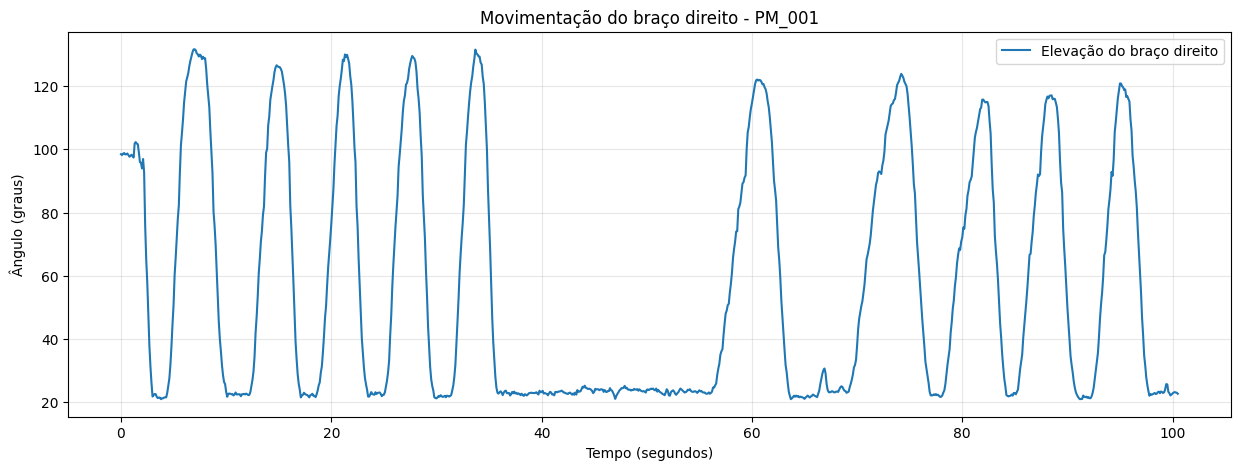

In [ ]:
# Gera um gráfico da elevação do braço direito ao longo do vídeo selecionado.
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    df_angulos_aplicacao["tempo_segundos"],
    df_angulos_aplicacao["elevacao_braco_direito"],
    label="Elevação do braço direito"
)

plt.xlabel("Tempo (segundos)")
plt.ylabel("Ângulo (graus)")
plt.title(f"Movimentação do braço direito - {video_escolhido}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Identifica os picos de elevação do braço direito para localizar possíveis repetições.
from scipy.signal import find_peaks

sinal_braco = df_angulos_aplicacao[
    "elevacao_braco_direito"
].to_numpy()

picos, propriedades = find_peaks(
    sinal_braco,
    prominence=35,
    distance=30
)

df_picos = df_angulos_aplicacao.iloc[picos][
    ["frame", "tempo_segundos", "elevacao_braco_direito"]
].copy()

df_picos = df_picos.reset_index(drop=True)
df_picos.index += 1
df_picos.index.name = "repeticao"

print("Possíveis repetições identificadas:", len(df_picos))
display(df_picos.round(2))

Possíveis repetições identificadas: 10


,frame,tempo_segundos,elevacao_braco_direito
repeticao,,,
1,210,7.0,131.65
2,444,14.8,126.57
3,639,21.3,130.00
4,831,27.7,129.52
5,1011,33.7,131.53
6,1815,60.5,122.07
7,2226,74.2,123.85
8,2460,82.0,115.72
9,2655,88.5,117.05


In [ ]:
# Identifica os limites de cada repetição a partir dos vales entre os picos de elevação.
from scipy.signal import find_peaks
import numpy as np

vales, _ = find_peaks(
    -sinal_braco,
    prominence=10,
    distance=10
)

limites_repeticoes = []

for i, pico in enumerate(picos):
    vales_anteriores = vales[vales < pico]
    vales_posteriores = vales[vales > pico]

    inicio = vales_anteriores[-1] if len(vales_anteriores) else 0
    fim = vales_posteriores[0] if len(vales_posteriores) else len(sinal_braco) - 1

    limites_repeticoes.append({
        "repeticao": i + 1,
        "frame_inicio": int(df_angulos_aplicacao.iloc[inicio]["frame"]),
        "frame_pico": int(df_angulos_aplicacao.iloc[pico]["frame"]),
        "frame_fim": int(df_angulos_aplicacao.iloc[fim]["frame"]),
        "duracao_segundos": round((fim - inicio) * 3 / 30, 2)
    })

df_limites_repeticoes = pd.DataFrame(limites_repeticoes)

display(df_limites_repeticoes)


,repeticao,frame_inicio,frame_pico,frame_fim,duracao_segundos
0,1,114,210,303,6.3
1,2,303,444,513,7.0
2,3,513,639,708,6.5
3,4,708,831,900,6.4
4,5,900,1011,1410,17.0
5,6,1410,1815,1911,16.7
6,7,1911,2226,2337,14.2
7,8,2337,2460,2532,6.5
8,9,2532,2655,2736,6.8
9,10,2736,2850,3015,9.3


In [ ]:
# Extrai as características de cada repetição e aplica o classificador treinado.
resultados_classificacao = []

for _, repeticao in df_limites_repeticoes.iterrows():

    inicio = repeticao["frame_inicio"]
    fim = repeticao["frame_fim"]

    segmento = df_angulos_aplicacao[
        (df_angulos_aplicacao["frame"] >= inicio) &
        (df_angulos_aplicacao["frame"] <= fim)
    ].copy()

    segmento = segmento.dropna(
        subset=["elevacao_braco_direito", "braco_direito"]
    )

    caracteristicas_repeticao = pd.DataFrame([{
        "elevacao_braco_max": segmento["elevacao_braco_direito"].max(),
        "elevacao_braco_desvio": segmento["elevacao_braco_direito"].std(),
        "braco_direito_medio": segmento["braco_direito"].mean()
    }], columns=caracteristicas_recarregadas)

    if segmento.empty or caracteristicas_repeticao.isna().any().any():
        continue

    previsao = modelo_recarregado.predict(caracteristicas_repeticao)[0]
    probabilidades = modelo_recarregado.predict_proba(
        caracteristicas_repeticao
    )[0]

    indice_correta = list(modelo_recarregado.classes_).index(1)

    resultados_classificacao.append({
        "repeticao": int(repeticao["repeticao"]),
        "classificacao": "Correta" if previsao == 1 else "Incorreta",
        "probabilidade_correta": probabilidades[indice_correta] * 100,
        "elevacao_maxima": caracteristicas_repeticao.iloc[0]["elevacao_braco_max"],
        "desvio_elevacao": caracteristicas_repeticao.iloc[0]["elevacao_braco_desvio"],
        "cotovelo_medio": caracteristicas_repeticao.iloc[0]["braco_direito_medio"]
    })

df_resultado_classificacao = pd.DataFrame(resultados_classificacao)

display(df_resultado_classificacao.round(2))

print("Total de repetições classificadas:", len(df_resultado_classificacao))
print("\nResumo das classificações:")
display(df_resultado_classificacao["classificacao"].value_counts())

,repeticao,classificacao,probabilidade_correta,elevacao_maxima,desvio_elevacao,cotovelo_medio
0,1,Correta,95.19,131.65,43.04,162.09
1,2,Correta,82.77,126.57,41.50,163.42
2,3,Correta,83.32,130.00,41.40,164.80
3,4,Correta,91.25,129.52,42.01,162.49
4,5,Correta,72.24,131.53,33.19,160.76
5,6,Incorreta,24.69,122.07,34.62,164.92
6,7,Incorreta,28.20,123.85,36.93,167.10
7,8,Incorreta,1.85,115.72,32.54,170.32
8,9,Incorreta,6.39,117.05,36.01,169.34
9,10,Incorreta,21.74,120.85,37.02,167.01


Total de repetições classificadas: 10

Resumo das classificações:


,count
classificacao,
Correta,5
Incorreta,5


Criação do relatório

1. Frame original


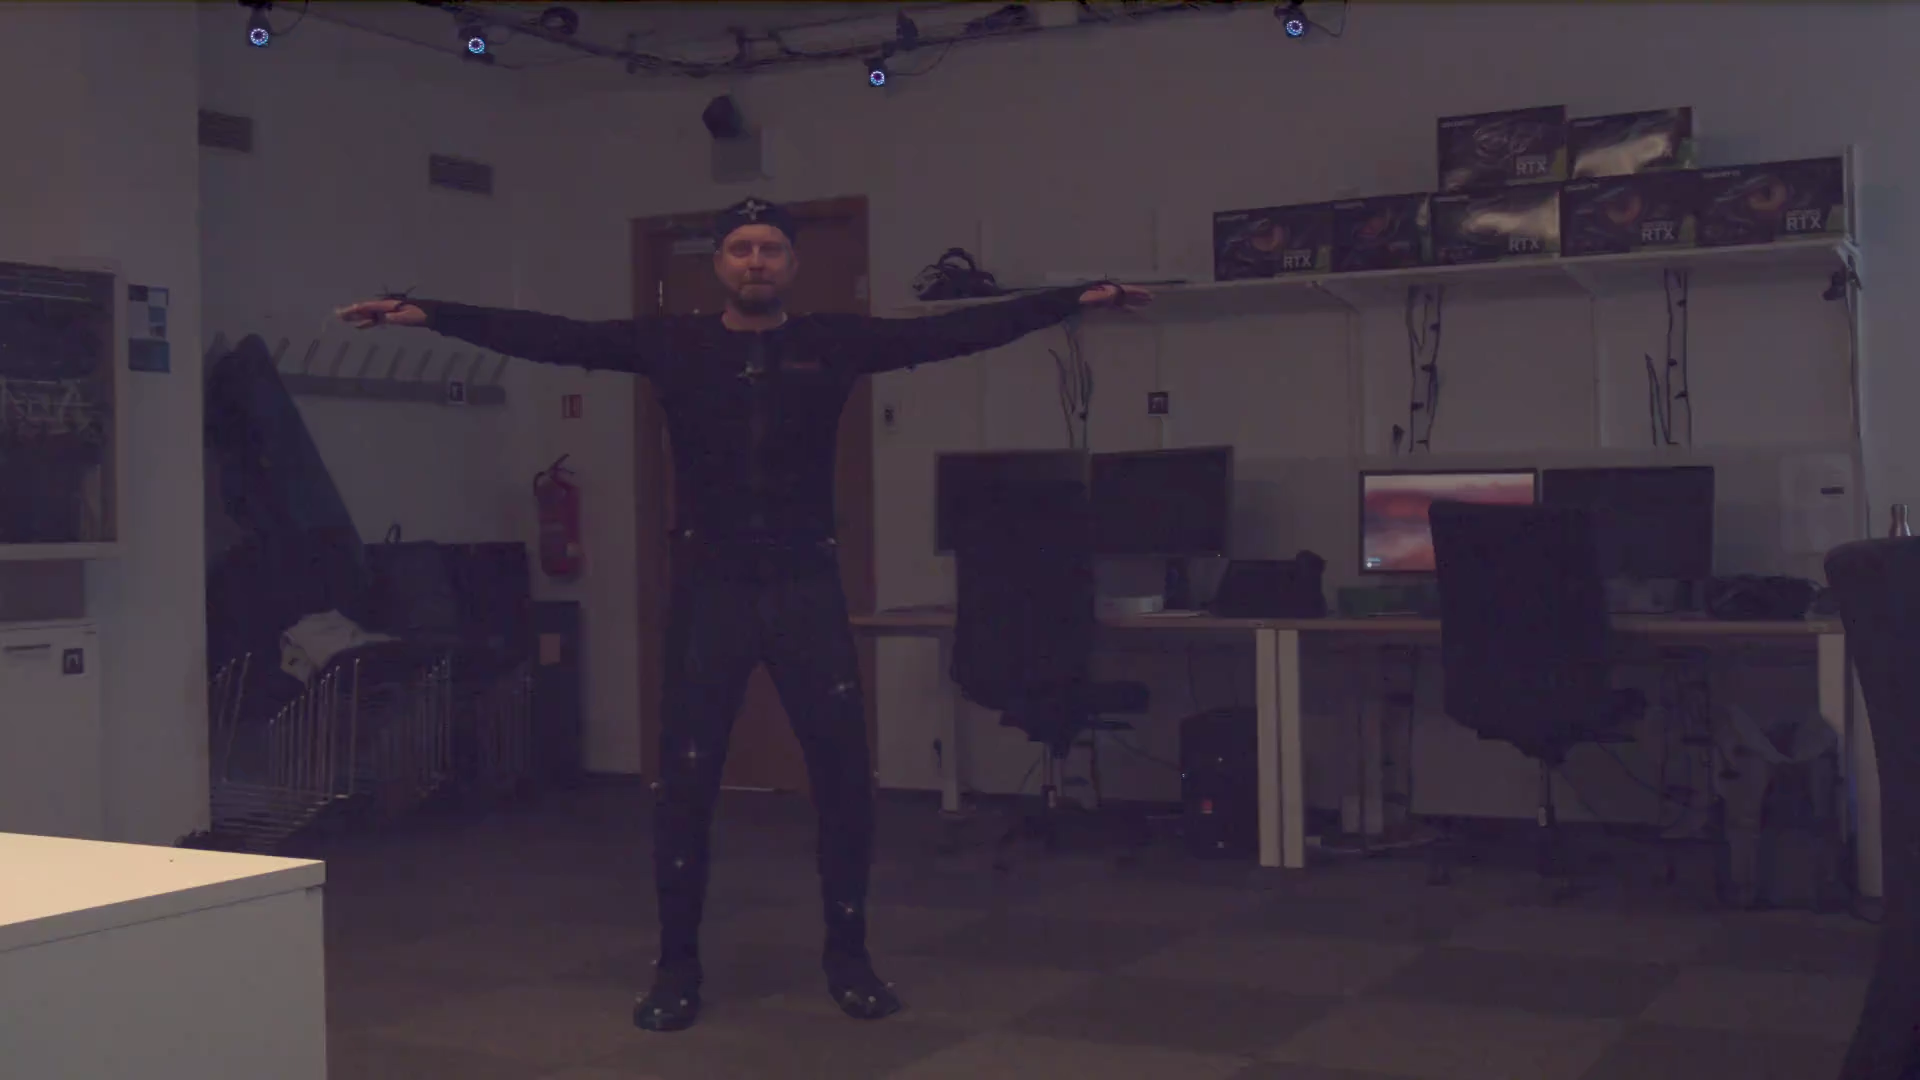

2. Detecções YOLOv8


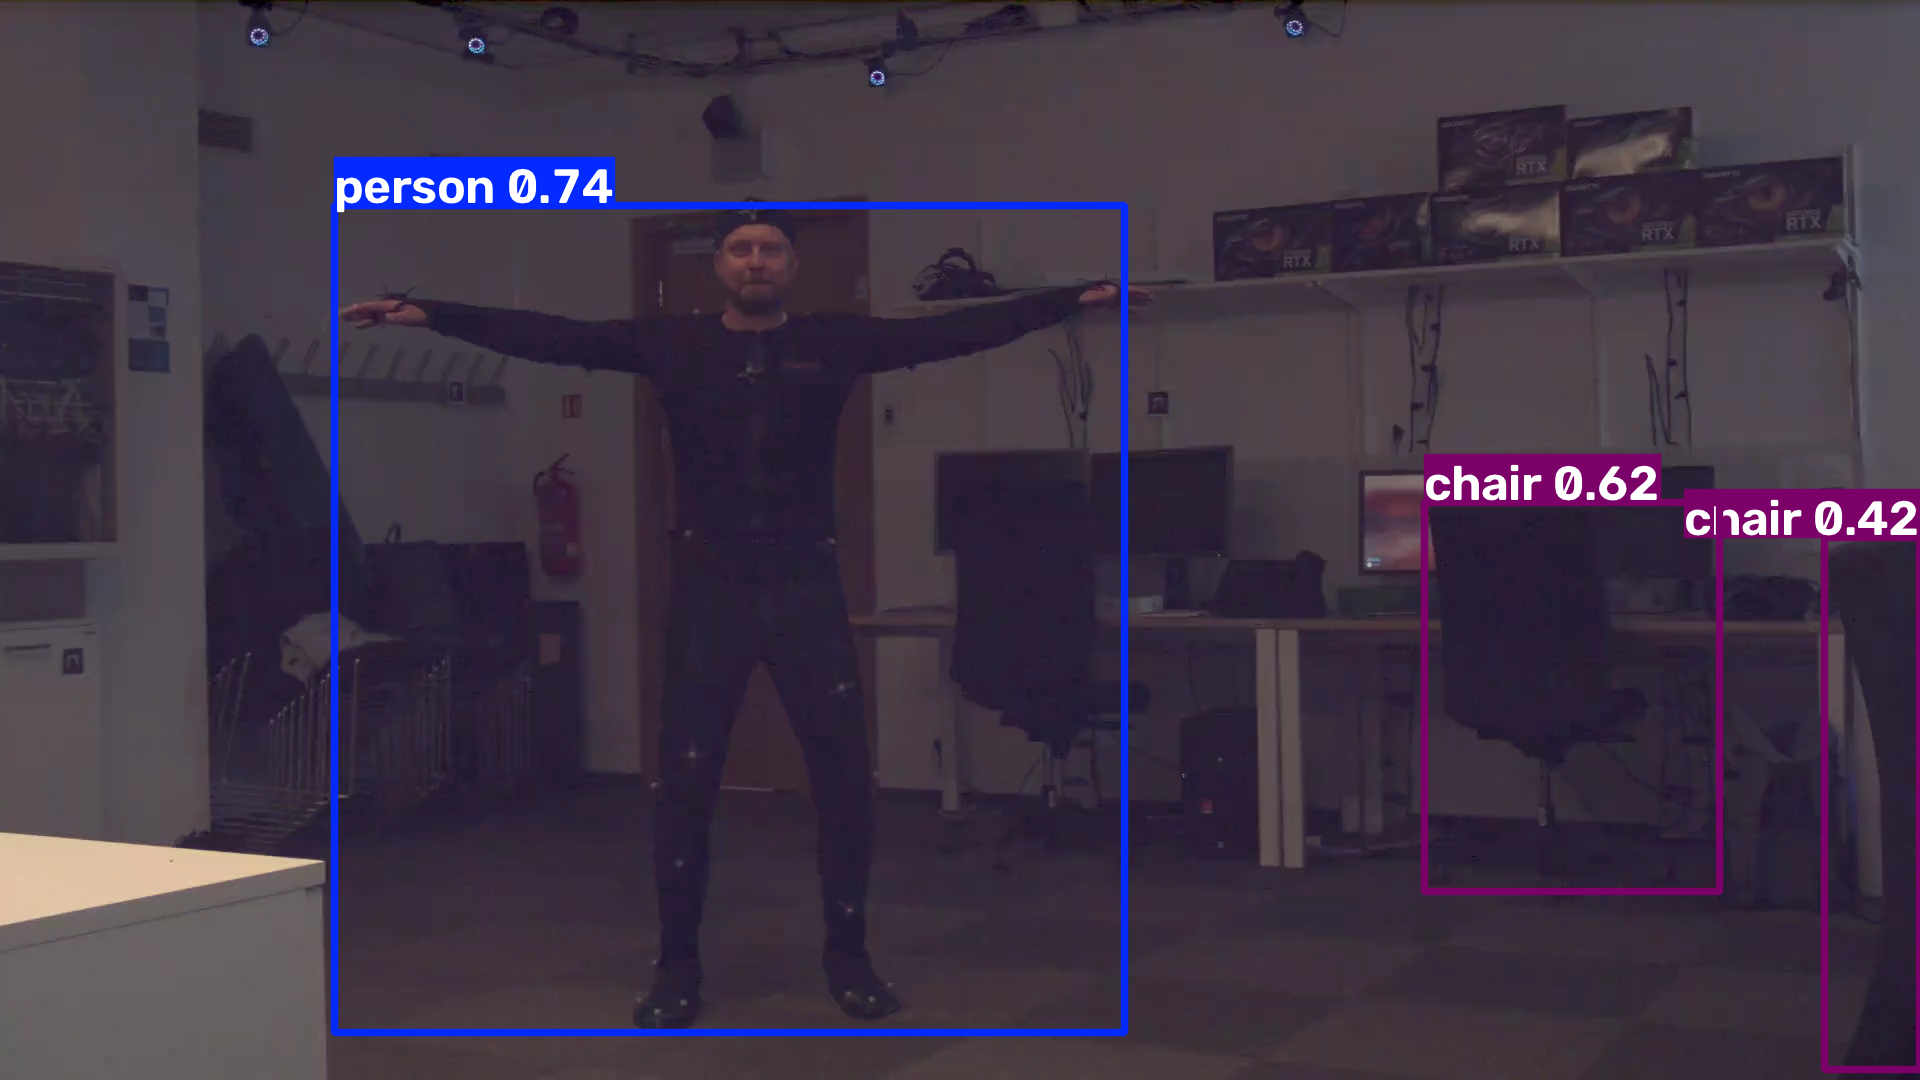

3. Detecções YOLOv8-Pose


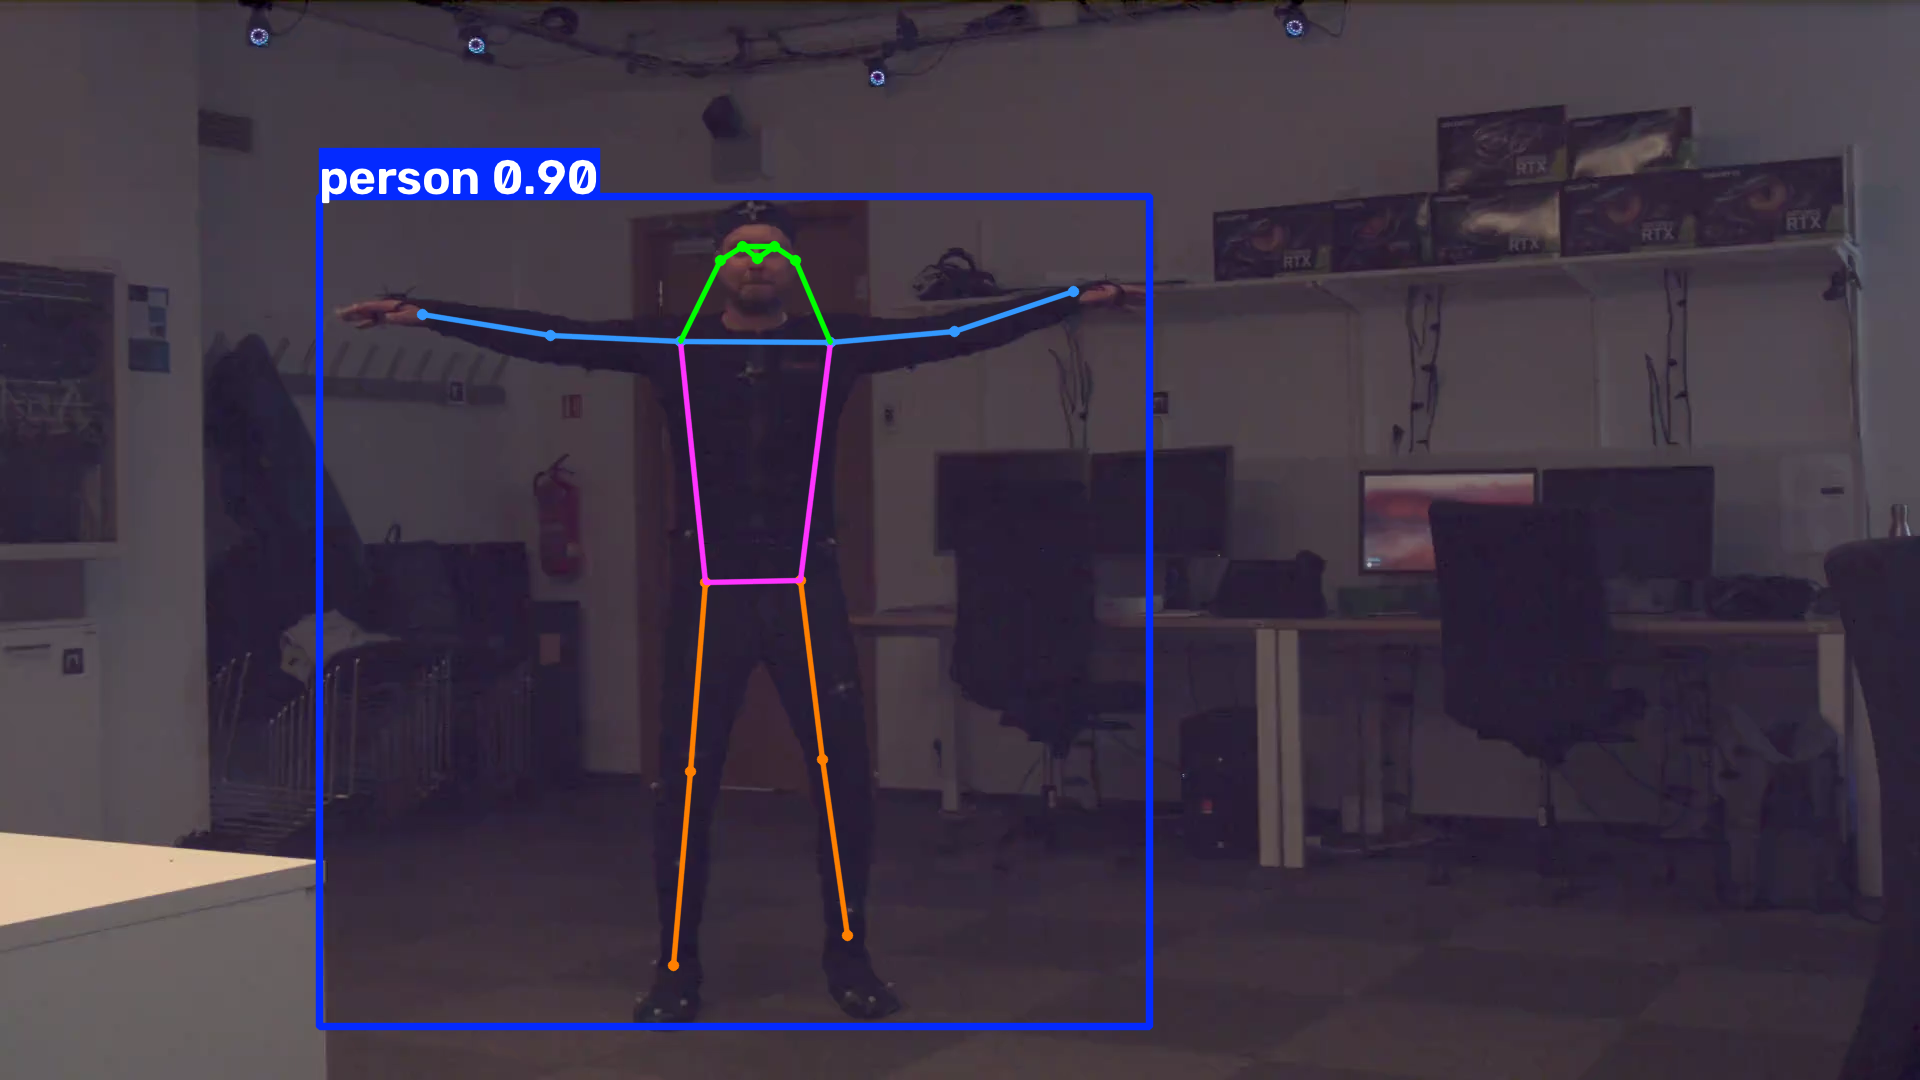

In [ ]:
# Extrai o primeiro frame do vídeo e gera as versões com detecções dos dois modelos.
import cv2
from IPython.display import display, Image

captura = cv2.VideoCapture(caminho_video_local)
sucesso, primeiro_frame = captura.read()
captura.release()

if not sucesso:
    raise ValueError("Não foi possível extrair o primeiro frame.")

# Salva o frame original.
cv2.imwrite("/content/primeiro_frame_original.png", primeiro_frame)

# Gera a imagem com as detecções do YOLOv8.
resultado_yolo = modelo_yolo.predict(
    primeiro_frame,
    conf=0.25,
    verbose=False
)[0]

imagem_yolo = resultado_yolo.plot()
cv2.imwrite("/content/primeiro_frame_yolo.png", imagem_yolo)

# Gera a imagem com os pontos corporais do YOLOv8-Pose.
resultado_pose = modelo_pose.predict(
    primeiro_frame,
    conf=0.25,
    verbose=False
)[0]

imagem_pose = resultado_pose.plot()
cv2.imwrite("/content/primeiro_frame_pose.png", imagem_pose)

# Exibe as três imagens para conferência.
print("1. Frame original")
display(Image(filename="/content/primeiro_frame_original.png"))

print("2. Detecções YOLOv8")
display(Image(filename="/content/primeiro_frame_yolo.png"))

print("3. Detecções YOLOv8-Pose")
display(Image(filename="/content/primeiro_frame_pose.png"))

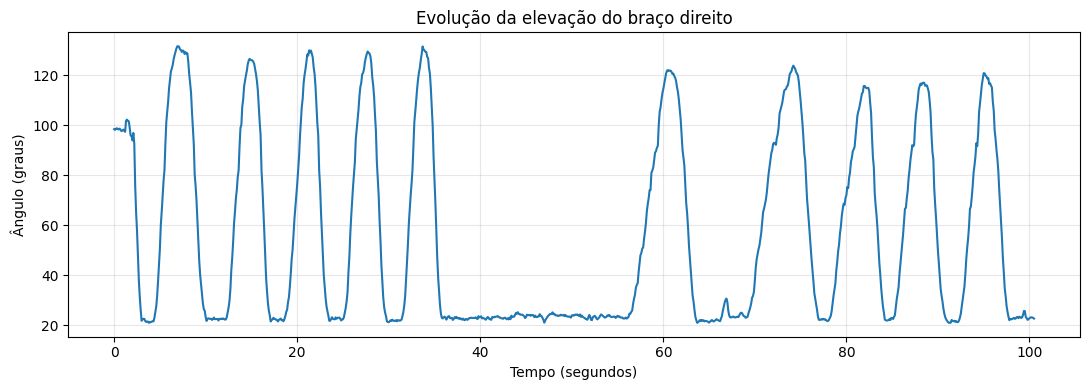

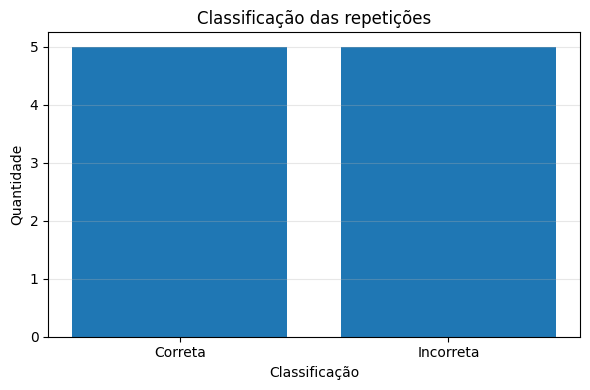

Gráficos salvos com sucesso.


In [ ]:
# Gera os gráficos de evolução do movimento e classificação das repetições.
import matplotlib.pyplot as plt

# Gráfico 1: evolução da elevação do braço direito.
plt.figure(figsize=(11, 4))
plt.plot(
    df_angulos_aplicacao["tempo_segundos"],
    df_angulos_aplicacao["elevacao_braco_direito"],
    linewidth=1.5
)
plt.title("Evolução da elevação do braço direito")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Ângulo (graus)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/grafico_elevacao_braco.png", dpi=200)
plt.show()

# Gráfico 2: distribuição das classificações.
contagem = df_resultado_classificacao["classificacao"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(contagem.index, contagem.values)
plt.title("Classificação das repetições")
plt.xlabel("Classificação")
plt.ylabel("Quantidade")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("/content/grafico_classificacao.png", dpi=200)
plt.show()

print("Gráficos salvos com sucesso.")

Gerar relatório

In [ ]:
# Monta o relatório técnico visual em PDF com imagens, tabelas, gráficos e resultados da análise.
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, KeepTogether
)
from reportlab.lib.utils import ImageReader
from datetime import datetime
import os

# Arquivo de saída.
caminho_pdf = "/content/relatorio_monitoramento.pdf"

# Paleta visual.
AZUL_ESCURO = colors.HexColor("#17365D")
AZUL = colors.HexColor("#2874A6")
AZUL_CLARO = colors.HexColor("#DCEAF4")
CINZA = colors.HexColor("#F2F4F6")
CINZA_TEXTO = colors.HexColor("#566573")
BRANCO = colors.white

# Configuração do documento.
documento = SimpleDocTemplate(
    caminho_pdf,
    pagesize=A4,
    rightMargin=1.7 * cm,
    leftMargin=1.7 * cm,
    topMargin=1.6 * cm,
    bottomMargin=1.6 * cm
)

# Estilos de texto.
estilos = getSampleStyleSheet()

estilos.add(ParagraphStyle(
    name="TituloPrincipal",
    parent=estilos["Title"],
    fontName="Helvetica-Bold",
    fontSize=21,
    leading=26,
    textColor=AZUL_ESCURO,
    alignment=TA_LEFT,
    spaceAfter=8
))

estilos.add(ParagraphStyle(
    name="Secao",
    parent=estilos["Heading1"],
    fontName="Helvetica-Bold",
    fontSize=15,
    leading=19,
    textColor=AZUL_ESCURO,
    spaceBefore=18,
    spaceAfter=9,
    keepWithNext=True
))

estilos.add(ParagraphStyle(
    name="Subsecao",
    parent=estilos["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=11,
    leading=14,
    textColor=AZUL,
    spaceBefore=10,
    spaceAfter=6,
    keepWithNext=True
))

estilos.add(ParagraphStyle(
    name="CorpoRelatorio",
    parent=estilos["BodyText"],
    fontName="Helvetica",
    fontSize=9,
    leading=13,
    textColor=colors.HexColor("#283747"),
    spaceAfter=6
))

estilos.add(ParagraphStyle(
    name="Legenda",
    parent=estilos["BodyText"],
    fontName="Helvetica-Oblique",
    fontSize=8,
    leading=10,
    alignment=TA_CENTER,
    textColor=CINZA_TEXTO,
    spaceAfter=10
))

estilos.add(ParagraphStyle(
    name="Destaque",
    parent=estilos["BodyText"],
    fontName="Helvetica-Bold",
    fontSize=11,
    leading=15,
    textColor=AZUL_ESCURO,
    alignment=TA_CENTER
))

# Funções auxiliares para imagens e tabelas.
def adicionar_imagem(story, caminho, largura_max=16.5*cm, altura_max=9*cm):
    imagem = Image(caminho)
    proporcao = min(
        largura_max / imagem.imageWidth,
        altura_max / imagem.imageHeight
    )
    imagem.drawWidth = imagem.imageWidth * proporcao
    imagem.drawHeight = imagem.imageHeight * proporcao
    imagem.hAlign = "CENTER"
    story.append(imagem)
    story.append(Spacer(1, 5))

def adicionar_tabela(story, dados, larguras=None, primeira_linha_cabecalho=True):
    tabela = Table(dados, colWidths=larguras, repeatRows=1 if primeira_linha_cabecalho else 0)
    tabela.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), AZUL_ESCURO),
        ("TEXTCOLOR", (0, 0), (-1, 0), BRANCO),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("LEADING", (0, 0), (-1, -1), 11),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#D5DDE5")),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("ALIGN", (1, 1), (-1, -1), "CENTER"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [BRANCO, CINZA]),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5)
    ]))
    story.append(tabela)
    story.append(Spacer(1, 10))

# Conteúdo do relatório.
story = []

# 1. Identificação.
story.append(Paragraph(
    "RELATÓRIO DE MONITORAMENTO DE EXERCÍCIOS",
    estilos["TituloPrincipal"]
))
story.append(Paragraph(
    "Análise automatizada de vídeo por visão computacional e inteligência artificial",
    estilos["CorpoRelatorio"]
))
story.append(Spacer(1, 8))

nome_video = os.path.basename(caminho_video_local)
captura_info = cv2.VideoCapture(caminho_video_local)
fps_video = captura_info.get(cv2.CAP_PROP_FPS)
total_frames = int(captura_info.get(cv2.CAP_PROP_FRAME_COUNT))
largura_video = int(captura_info.get(cv2.CAP_PROP_FRAME_WIDTH))
altura_video = int(captura_info.get(cv2.CAP_PROP_FRAME_HEIGHT))
captura_info.release()

duracao_video = total_frames / fps_video if fps_video else 0

dados_identificacao = [
    ["INFORMAÇÃO", "RESULTADO"],
    ["Vídeo analisado", nome_video],
    ["Exercício", "Exercício 1 — elevação do braço direito"],
    ["Resolução", f"{largura_video} × {altura_video} pixels"],
    ["Taxa de quadros", f"{fps_video:.2f} FPS"],
    ["Duração", f"{duracao_video:.2f} segundos"],
    ["Data de geração", datetime.now().strftime("%d/%m/%Y %H:%M")]
]
adicionar_tabela(story, dados_identificacao, [5*cm, 11.5*cm])

# 2. YOLOv8.
story.append(Paragraph("2. DETECÇÃO DE OBJETOS — YOLOv8", estilos["Secao"]))
story.append(Paragraph(
    "O modelo YOLOv8 foi utilizado para identificar pessoas e objetos presentes "
    "nas imagens do vídeo. As detecções são realizadas quadro a quadro.",
    estilos["CorpoRelatorio"]
))

story.append(Paragraph("Frame original", estilos["Subsecao"]))
adicionar_imagem(story, "/content/primeiro_frame_original.png")
story.append(Paragraph(
    "Figura 1 — Primeiro frame do vídeo original, sem marcações de detecção.",
    estilos["Legenda"]
))

story.append(Paragraph("Frame com detecções do YOLOv8", estilos["Subsecao"]))
adicionar_imagem(story, "/content/primeiro_frame_yolo.png")
story.append(Paragraph(
    "Figura 2 — Primeiro frame processado pelo YOLOv8, com as classes e caixas de detecção.",
    estilos["Legenda"]
))

# Resumo das detecções acumuladas na análise anterior.
dados_deteccoes = [["OBJETO", "DETECÇÕES ACUMULADAS"]]
for objeto, quantidade in [
    ("Pessoa", 1308),
    ("Cadeira", 1996),
    ("Mesa de jantar", 289),
    ("Sofá", 4),
    ("Televisão", 1),
    ("Cavalo", 1)
]:
    dados_deteccoes.append([objeto, str(quantidade)])

adicionar_tabela(story, dados_deteccoes, [9*cm, 7.5*cm])
story.append(Paragraph(
    "Nota: as quantidades representam detecções acumuladas nos frames analisados, "
    "não correspondem necessariamente a objetos ou pessoas únicos. Detecções isoladas "
    "podem conter falsos positivos.",
    estilos["CorpoRelatorio"]
))

# 3. YOLOv8-Pose.
story.append(Paragraph("3. DETECÇÃO DE POSE — YOLOv8-POSE", estilos["Secao"]))
story.append(Paragraph(
    "O YOLOv8-Pose foi utilizado para localizar os pontos corporais da pessoa "
    "identificada, permitindo acompanhar sua movimentação ao longo do vídeo.",
    estilos["CorpoRelatorio"]
))

story.append(Paragraph("Frame com detecção de pose", estilos["Subsecao"]))
adicionar_imagem(story, "/content/primeiro_frame_pose.png")
story.append(Paragraph(
    "Figura 3 — Primeiro frame processado pelo YOLOv8-Pose, com pontos corporais e conexões do esqueleto.",
    estilos["Legenda"]
))

dados_pose = [
    ["INDICADOR", "RESULTADO"],
    ["Frames processados", "1.006"],
    ["Registros de pontos corporais", f"{len(df_pose_aplicacao):,}".replace(",", ".")],
    ["Pontos corporais por frame", "17"],
    ["Pessoa principal acompanhada", "ID 1"],
    ["Frames acompanhados da pessoa principal", f"{df_pessoa_principal['frame'].nunique():,}".replace(",", ".")]
]
adicionar_tabela(story, dados_pose, [9*cm, 7.5*cm])

story.append(Paragraph(
    "O identificador da pessoa é temporário e pertence ao rastreamento do vídeo. "
    "Os 17 pontos correspondem ao padrão COCO utilizado pelo modelo, não aos 26 pontos "
    "disponíveis nos dados de referência do REHAB24-6.",
    estilos["CorpoRelatorio"]
))

# 4. Análise dos movimentos.
story.append(Paragraph("4. ANÁLISE DOS MOVIMENTOS", estilos["Secao"]))
story.append(Paragraph(
    "A partir dos pontos corporais, foram estimados ângulos articulares no plano da imagem. "
    "Os valores são estimativas geométricas em duas dimensões, não medidas anatômicas clínicas.",
    estilos["CorpoRelatorio"]
))

colunas_angulos = [
    ("braco_esquerdo", "Cotovelo esquerdo"),
    ("braco_direito", "Cotovelo direito"),
    ("perna_esquerda", "Joelho esquerdo"),
    ("perna_direita", "Joelho direito"),
    ("inclinacao_tronco", "Inclinação do tronco"),
    ("elevacao_braco_direito", "Elevação do braço direito")
]

dados_angulos = [["ÂNGULO", "MÉDIA (°)", "MÍNIMO (°)", "MÁXIMO (°)"]]
for coluna, nome in colunas_angulos:
    serie = df_angulos_aplicacao[coluna].dropna()
    dados_angulos.append([
        nome,
        f"{serie.mean():.2f}",
        f"{serie.min():.2f}",
        f"{serie.max():.2f}"
    ])

adicionar_tabela(story, dados_angulos, [7*cm, 3.2*cm, 3.2*cm, 3.2*cm])

story.append(Paragraph("Evolução da elevação do braço direito", estilos["Subsecao"]))
adicionar_imagem(story, "/content/grafico_elevacao_braco.png", altura_max=8*cm)
story.append(Paragraph(
    "Figura 4 — Variação do ângulo estimado de elevação do braço direito ao longo do vídeo.",
    estilos["Legenda"]
))

# 5. Repetições e classificação.
story.append(Paragraph("5. CONTAGEM E CLASSIFICAÇÃO DAS REPETIÇÕES", estilos["Secao"]))
total_repeticoes = len(df_resultado_classificacao)
contagem_classificacao = df_resultado_classificacao["classificacao"].value_counts()

corretas = int(contagem_classificacao.get("Correta", 0))
incorretas = int(contagem_classificacao.get("Incorreta", 0))

dados_resumo = [
    ["INDICADOR", "RESULTADO"],
    ["Total de repetições classificadas", str(total_repeticoes)],
    ["Repetições classificadas como corretas", str(corretas)],
    ["Repetições classificadas como incorretas", str(incorretas)]
]
adicionar_tabela(story, dados_resumo, [10*cm, 6.5*cm])

story.append(Paragraph("Classificação individual", estilos["Subsecao"]))

dados_repeticoes = [[
    "Repetição", "Classificação", "Prob. correta (%)",
    "Elevação máx. (°)", "Desvio", "Cotovelo médio (°)"
]]

for _, linha in df_resultado_classificacao.iterrows():
    dados_repeticoes.append([
        str(int(linha["repeticao"])),
        linha["classificacao"],
        f'{linha["probabilidade_correta"]:.2f}',
        f'{linha["elevacao_maxima"]:.2f}',
        f'{linha["desvio_elevacao"]:.2f}',
        f'{linha["cotovelo_medio"]:.2f}'
    ])

adicionar_tabela(
    story,
    dados_repeticoes,
    [1.5*cm, 2.5*cm, 3*cm, 3*cm, 2.5*cm, 4*cm]
)

story.append(Paragraph("Distribuição das classificações", estilos["Subsecao"]))
adicionar_imagem(story, "/content/grafico_classificacao.png", largura_max=12*cm, altura_max=7*cm)
story.append(Paragraph(
    "Figura 5 — Quantidade de repetições classificadas em cada categoria.",
    estilos["Legenda"]
))

# 6. Conclusão e limitações.
story.append(Paragraph("6. CONCLUSÃO E LIMITAÇÕES", estilos["Secao"]))
story.append(Paragraph(
    f"A análise processou o vídeo {nome_video}, identificou a pessoa acompanhada "
    f"e classificou {total_repeticoes} repetições: {corretas} como corretas e "
    f"{incorretas} como incorretas, segundo o modelo experimental utilizado.",
    estilos["CorpoRelatorio"]
))

story.append(Paragraph(
    "<b>Limitações:</b> a segmentação por picos e vales é uma aproximação baseada "
    "na variação do ângulo selecionado. O classificador foi treinado com apenas dez "
    "repetições do vídeo de referência PM_001, e as mesmas amostras foram utilizadas "
    "nesta demonstração. Portanto, os resultados não constituem validação independente "
    "nem demonstram generalização para outros indivíduos ou exercícios. Os ângulos "
    "estimados a partir de imagens 2D não substituem avaliação profissional ou clínica.",
    estilos["CorpoRelatorio"]
))

story.append(Spacer(1, 12))
story.append(Paragraph(
    "Relatório gerado automaticamente pelo sistema experimental de monitoramento.",
    estilos["Legenda"]
))

# Numeração de páginas e identificação no rodapé.
def rodape(canvas, doc):
    canvas.saveState()
    largura, altura = A4
    canvas.setStrokeColor(AZUL_CLARO)
    canvas.line(1.7*cm, 1.2*cm, largura-1.7*cm, 1.2*cm)
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(CINZA_TEXTO)
    canvas.drawString(1.7*cm, 0.8*cm, "Relatório de Monitoramento de Exercícios")
    canvas.drawRightString(largura-1.7*cm, 0.8*cm, f"Página {doc.page}")
    canvas.restoreState()

# Constrói o PDF.
documento.build(story, onFirstPage=rodape, onLaterPages=rodape)

print("Relatório PDF gerado com sucesso!")
print("Arquivo:", caminho_pdf)
print("Tamanho:", round(os.path.getsize(caminho_pdf) / 1024, 2), "KB")

Relatório PDF gerado com sucesso!
Arquivo: /content/relatorio_monitoramento.pdf
Tamanho: 2860.93 KB


##Áudio

In [ ]:
# Baixa o repositório oficial do conjunto de dados.
!git clone https://github.com/babylonhealth/primock57.git /content/primock57

# Verifica a estrutura e a quantidade de arquivos baixados.
import os

caminho_dataset = "/content/primock57"

for pasta in ["audio", "transcripts", "notes"]:
    caminho = os.path.join(caminho_dataset, pasta)

    arquivos = os.listdir(caminho) if os.path.exists(caminho) else []

    print(f"{pasta}: {len(arquivos)} arquivos")

# Conta os arquivos WAV.
arquivos_audio = []

for raiz, diretorios, arquivos in os.walk(
    os.path.join(caminho_dataset, "audio")
):
    for arquivo in arquivos:
        if arquivo.lower().endswith(".wav"):
            arquivos_audio.append(os.path.join(raiz, arquivo))

print("\nTotal de arquivos WAV:", len(arquivos_audio))

Cloning into '/content/primock57'...
remote: Enumerating objects: 424, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 424 (delta 14), reused 14 (delta 14), pack-reused 404 (from 1)
Receiving objects: 100% (424/424), 3.83 MiB | 12.00 MiB/s, done.
Resolving deltas: 100% (59/59), done.
Filtering content: 100% (114/114), 1.85 GiB | 30.80 MiB/s, done.
audio: 115 arquivos
transcripts: 115 arquivos
notes: 58 arquivos

Total de arquivos WAV: 114


##Treinamento

In [ ]:
# Verifica o tamanho e as propriedades técnicas do áudio selecionado.
import os
import soundfile as sf

caminho_audio = (
    "/content/primock57/audio/day1_consultation01_patient.wav"
)

if os.path.exists(caminho_audio):
    informacoes = sf.info(caminho_audio)

    print("Arquivo:", os.path.basename(caminho_audio))
    print(f"Tamanho: {os.path.getsize(caminho_audio) / (1024**2):.2f} MB")
    print("Duração:", round(informacoes.duration, 2), "segundos")
    print("Frequência:", informacoes.samplerate, "Hz")
    print("Canais:", informacoes.channels)
    print("Formato:", informacoes.format)
else:
    print("Arquivo não encontrado no caminho informado.")

Arquivo: day1_consultation01_patient.wav
Tamanho: 13.97 MB
Duração: 457.86 segundos
Frequência: 16000 Hz
Canais: 1
Formato: WAV


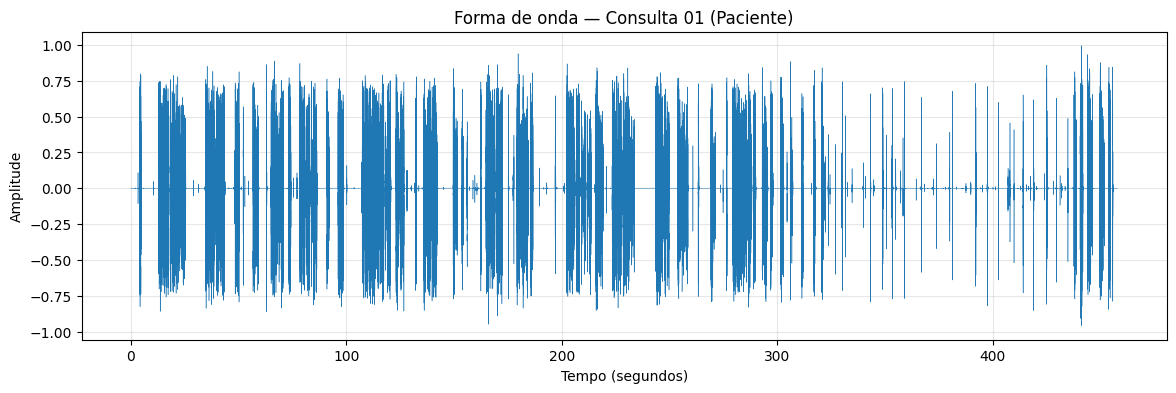

In [ ]:
# Carrega o áudio e apresenta a evolução da amplitude ao longo do tempo.
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np

audio, taxa = sf.read(caminho_audio)

tempo = np.arange(len(audio)) / taxa

plt.figure(figsize=(14, 4))
plt.plot(tempo, audio, linewidth=0.35)
plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude")
plt.title("Forma de onda — Consulta 01 (Paciente)")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Extrai frequência fundamental, intensidade e períodos de silêncio do áudio.
import numpy as np
import pandas as pd
import librosa

# Define os parâmetros de análise.
hop_length = 512
frame_length = 2048

# Calcula a intensidade RMS de cada janela.
rms = librosa.feature.rms(
    y=audio,
    frame_length=frame_length,
    hop_length=hop_length
)[0]

# Calcula a frequência fundamental estimada.
f0 = librosa.yin(
    audio,
    fmin=65,
    fmax=400,
    sr=taxa,
    frame_length=frame_length,
    hop_length=hop_length
)

# Mantém estimativas de F0 apenas em janelas com energia suficiente.
limite_energia = np.percentile(rms, 20)
mascara_vozeada = rms > limite_energia
f0_valida = f0[mascara_vozeada]

# Converte a intensidade RMS para decibéis.
intensidade_db = librosa.amplitude_to_db(
    rms,
    ref=1.0
)

# Identifica intervalos considerados silenciosos.
intervalos_som = librosa.effects.split(
    audio,
    top_db=35,
    frame_length=1024,
    hop_length=160
)

# Calcula as pausas entre intervalos de som.
pausas = []

for i in range(1, len(intervalos_som)):
    inicio_pausa = intervalos_som[i - 1][1] / taxa
    fim_pausa = intervalos_som[i][0] / taxa
    duracao = fim_pausa - inicio_pausa

    if duracao >= 0.3:
        pausas.append(duracao)

# Organiza os resultados.
resultados_acusticos = pd.DataFrame({
    "indicador": [
        "F0 média (Hz)",
        "F0 mediana (Hz)",
        "F0 desvio padrão (Hz)",
        "Intensidade média (dBFS)",
        "Intensidade máxima (dBFS)",
        "Quantidade de pausas >= 0,3 s",
        "Duração média das pausas (s)",
        "Tempo total de pausas (s)"
    ],
    "valor": [
        np.mean(f0_valida) if len(f0_valida) else np.nan,
        np.median(f0_valida) if len(f0_valida) else np.nan,
        np.std(f0_valida) if len(f0_valida) else np.nan,
        np.mean(intensidade_db),
        np.max(intensidade_db),
        len(pausas),
        np.mean(pausas) if pausas else 0,
        np.sum(pausas)
    ]
})

display(resultados_acusticos.round(2))

,indicador,valor
0,F0 média (Hz),219.92
1,F0 mediana (Hz),183.89
2,F0 desvio padrão (Hz),122.12
3,Intensidade média (dBFS),-60.62
4,Intensidade máxima (dBFS),-8.70
5,"Quantidade de pausas >= 0,3 s",123.00
6,Duração média das pausas (s),2.35
7,Tempo total de pausas (s),288.67


In [ ]:
# Refina F0 com pYIN e calcula intensidade apenas nos trechos com som.
import numpy as np
import pandas as pd
import librosa

hop_length = 512
frame_length = 2048

# Estima a frequência fundamental e identifica quadros vozeados.
f0_pyin, voiced_flag, voiced_probability = librosa.pyin(
    audio,
    fmin=65,
    fmax=400,
    sr=taxa,
    frame_length=frame_length,
    hop_length=hop_length
)

f0_refinada = f0_pyin[voiced_flag & ~np.isnan(f0_pyin)]

# Calcula a intensidade RMS por janela.
rms_refinado = librosa.feature.rms(
    y=audio,
    frame_length=frame_length,
    hop_length=hop_length
)[0]

# Identifica os trechos com som.
intervalos_som = librosa.effects.split(
    audio,
    top_db=35,
    frame_length=1024,
    hop_length=160
)

# Seleciona as janelas de intensidade que pertencem aos trechos com som.
tempos_quadros = librosa.frames_to_time(
    np.arange(len(rms_refinado)),
    sr=taxa,
    hop_length=hop_length
)

mascara_som = np.zeros(len(rms_refinado), dtype=bool)

for inicio, fim in intervalos_som:
    inicio_seg = inicio / taxa
    fim_seg = fim / taxa
    mascara_som |= (
        (tempos_quadros >= inicio_seg) &
        (tempos_quadros <= fim_seg)
    )

rms_som = rms_refinado[mascara_som]
intensidade_som_db = librosa.amplitude_to_db(rms_som, ref=1.0)

# Organiza os indicadores refinados.
resultados_refinados = pd.DataFrame({
    "indicador": [
        "F0 média (Hz)",
        "F0 mediana (Hz)",
        "F0 desvio padrão (Hz)",
        "Percentual de quadros vozeados",
        "Intensidade média nos trechos com som (dBFS)",
        "Intensidade máxima nos trechos com som (dBFS)"
    ],
    "valor": [
        np.mean(f0_refinada),
        np.median(f0_refinada),
        np.std(f0_refinada),
        100 * np.mean(voiced_flag),
        np.mean(intensidade_som_db),
        np.max(intensidade_som_db)
    ]
})

display(resultados_refinados.round(2))

,indicador,valor
0,F0 média (Hz),125.71
1,F0 mediana (Hz),104.98
2,F0 desvio padrão (Hz),58.64
3,Percentual de quadros vozeados,14.25
4,Intensidade média nos trechos com som (dBFS),-19.95
5,Intensidade máxima nos trechos com som (dBFS),-8.70


Optou-se pelo método pYIN para as análises seguintes, pois permite identificar os trechos vozeados e filtrar estimativas de F0 em segmentos sem voz, tornando a análise mais consistente. Os resultados do YIN foram mantidos apenas para comparação metodológica.Optou-se pelo método pYIN para as análises seguintes, pois permite identificar os trechos vozeados e filtrar estimativas de F0 em segmentos sem voz, tornando a análise mais consistente. Os resultados do YIN foram mantidos apenas para comparação metodológica.

Azure AI Speech

In [ ]:
# Valida as credenciais do Azure Speech e do Azure AI Language.
from google.colab import userdata
import requests
import azure.cognitiveservices.speech as speechsdk

# 1. Recupera as credenciais dos dois serviços.
AZURE_SPEECH_KEY = userdata.get("AZURE_SPEECH_KEY")
AZURE_SPEECH_REGION = "brazilsouth"

AZURE_LANGUAGE_KEY = userdata.get("AZURE_LANGUAGE_KEY")
AZURE_LANGUAGE_ENDPOINT = userdata.get("AZURE_LANGUAGE_ENDPOINT")

print("=== VALIDAÇÃO DAS CREDENCIAIS ===")
print("Speech - Chave configurada:", bool(AZURE_SPEECH_KEY))
print("Speech - Região:", AZURE_SPEECH_REGION)
print("Language - Chave configurada:", bool(AZURE_LANGUAGE_KEY))
print("Language - Endpoint configurado:", bool(AZURE_LANGUAGE_ENDPOINT))

# 2. Valida a configuração do Azure Speech.
print("\n=== AZURE SPEECH ===")

if AZURE_SPEECH_KEY:
    try:
        speech_config = speechsdk.SpeechConfig(
            subscription=AZURE_SPEECH_KEY,
            region=AZURE_SPEECH_REGION
        )
        speech_config.speech_recognition_language = "en-US"

        print("Configuração do Speech criada com sucesso.")
        print("A autenticação será confirmada durante o reconhecimento de áudio.")
    except Exception as erro:
        print("Falha na configuração do Speech:", str(erro))
else:
    print("Chave do Speech não encontrada.")

# 3. Valida o Azure AI Language com uma requisição real.
print("\n=== AZURE AI LANGUAGE ===")

if AZURE_LANGUAGE_KEY and AZURE_LANGUAGE_ENDPOINT:
    try:
        url = (
            AZURE_LANGUAGE_ENDPOINT.rstrip("/")
            + "/language/:analyze-text?api-version=2022-05-01"
        )

        cabecalhos = {
            "Ocp-Apim-Subscription-Key": AZURE_LANGUAGE_KEY,
            "Content-Type": "application/json"
        }

        dados = {
            "kind": "EntityRecognition",
            "parameters": {
                "modelVersion": "latest"
            },
            "analysisInput": {
                "documents": [
                    {
                        "id": "1",
                        "language": "en",
                        "text": "The patient reports headache and fever."
                    }
                ]
            }
        }

        resposta = requests.post(
            url,
            headers=cabecalhos,
            json=dados,
            timeout=60
        )

        print("Código HTTP:", resposta.status_code)

        if resposta.status_code == 200:
            print("Azure AI Language: conexão e autenticação confirmadas.")
            resultado_teste = resposta.json()
            entidades = resultado_teste.get("results", {}).get(
                "documents", [{}]
            )[0].get("entities", [])

            print("Entidades identificadas no teste:")
            for entidade in entidades:
                print("-", entidade["text"], "|", entidade["category"])

        else:
            print("Falha na validação do Language.")
            print(resposta.text[:1000])

    except Exception as erro:
        print("Erro na conexão com Azure Language:", str(erro))
else:
    print("Credenciais do Language incompletas.")

=== VALIDAÇÃO DAS CREDENCIAIS ===
Speech - Chave configurada: True
Speech - Região: brazilsouth
Language - Chave configurada: True
Language - Endpoint configurado: True

=== AZURE SPEECH ===
Configuração do Speech criada com sucesso.
A autenticação será confirmada durante o reconhecimento de áudio.

=== AZURE AI LANGUAGE ===
Código HTTP: 200
Azure AI Language: conexão e autenticação confirmadas.
Entidades identificadas no teste:
- patient | PersonType


In [ ]:
# Acessa o repositório oficial do PriMock57 e lista os arquivos de áudio disponíveis.
import os
import subprocess

repositorio = "/content/primock57"

# Instala o Git LFS, necessário para baixar os áudios posteriormente.
subprocess.run(["apt-get", "-qq", "update"], check=True)
subprocess.run(["apt-get", "-qq", "install", "-y", "git-lfs"], check=True)
subprocess.run(["git", "lfs", "install"], check=True)

# Clona apenas a estrutura do repositório, sem baixar os áudios.
if not os.path.exists(repositorio):
    ambiente = os.environ.copy()
    ambiente["GIT_LFS_SKIP_SMUDGE"] = "1"

    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/babylonhealth/primock57.git", repositorio],
        env=ambiente,
        check=True
    )

# Identifica e organiza os arquivos WAV.
pasta_audio = os.path.join(repositorio, "audio")
arquivos_audio = sorted(
    arquivo for arquivo in os.listdir(pasta_audio)
    if arquivo.lower().endswith(".wav")
)

print(f"Total de arquivos encontrados: {len(arquivos_audio)}\n")

for numero, arquivo in enumerate(arquivos_audio, start=1):
    print(f"{numero:02d} - {arquivo}")
    print("Arquivo não encontrado. Verifique o nome e o local.")

In [ ]:
# Solicita o nome do áudio, verifica sua existência no PriMock57 e realiza o download.
import os
import subprocess

nome_arquivo = input("Digite o nome do arquivo de áudio (.wav): ").strip()

if nome_arquivo not in arquivos_audio:
    print("Arquivo não encontrado. Verifique o nome na lista de áudios.")
else:
    resultado = subprocess.run(
        ["git", "lfs", "pull", "--include=audio/" + nome_arquivo],
        cwd="/content/primock57",
        capture_output=True,
        text=True
    )

    caminho_audio = os.path.join("/content/primock57/audio", nome_arquivo)

    if resultado.returncode == 0 and os.path.exists(caminho_audio):
        print("Download concluído!")
        print("Arquivo:", nome_arquivo)
        print("Caminho:", caminho_audio)
    else:
        print("Não foi possível baixar o arquivo.")
        print(resultado.stderr)

In [ ]:
# Realiza a transcrição contínua do áudio selecionado usando o Azure Speech.
!pip -q install azure-cognitiveservices-speech

import os
import threading
import azure.cognitiveservices.speech as speechsdk
from google.colab import userdata

# Verifica se o áudio selecionado está disponível.
if "caminho_audio" not in globals() or not os.path.exists(caminho_audio):
    raise FileNotFoundError("Áudio não encontrado. Selecione e baixe o arquivo primeiro.")

# Recupera a chave do Azure armazenada nos Secrets do Colab.
chave = userdata.get("AZURE_SPEECH_KEY")

if not chave:
    raise ValueError("A chave AZURE_SPEECH_KEY não foi encontrada nos Secrets.")

# Configura o serviço de reconhecimento de fala.
config = speechsdk.SpeechConfig(
    subscription=chave,
    region="brazilsouth"
)
config.speech_recognition_language = "en-US"

audio_config = speechsdk.audio.AudioConfig(filename=caminho_audio)
reconhecedor = speechsdk.SpeechRecognizer(
    speech_config=config,
    audio_config=audio_config
)

trechos_transcritos = []
erros_azure = []
concluido = threading.Event()

def ao_reconhecer(evento):
    if evento.result.reason == speechsdk.ResultReason.RecognizedSpeech:
        trechos_transcritos.append(evento.result.text)

def ao_cancelar(evento):
    detalhes = evento.result.cancellation_details
    if detalhes.reason == speechsdk.CancellationReason.Error:
        erros_azure.append(detalhes.error_details or str(detalhes.reason))
    concluido.set()

def ao_finalizar(evento):
    concluido.set()

reconhecedor.recognized.connect(ao_reconhecer)
reconhecedor.canceled.connect(ao_cancelar)
reconhecedor.session_stopped.connect(ao_finalizar)

print("Iniciando transcrição...")
reconhecedor.start_continuous_recognition_async().get()

concluiu = concluido.wait(timeout=900)

reconhecedor.stop_continuous_recognition_async().get()

if erros_azure:
    raise RuntimeError("Erro no Azure Speech: " + "; ".join(erros_azure))

if not concluiu:
    raise TimeoutError("O tempo limite da transcrição foi atingido.")

if not trechos_transcritos:
    raise RuntimeError("O Azure não retornou trechos de fala reconhecidos.")

# Consolida e salva o texto transcrito.
transcricao_azure = " ".join(trechos_transcritos)

caminho_transcricao = caminho_audio.rsplit(".", 1)[0] + "_transcricao.txt"

with open(caminho_transcricao, "w", encoding="utf-8") as arquivo:
    arquivo.write(transcricao_azure)

print("\nTranscrição concluída!")
print("Trechos reconhecidos:", len(trechos_transcritos))
print("Arquivo salvo em:", caminho_transcricao)
print("\nTexto transcrito:\n")
print(transcricao_azure)

In [ ]:
# Executa a análise de sentimento da transcrição usando o Azure AI Language.
import requests
import re
import pandas as pd
from google.colab import userdata

# Recupera as credenciais do Azure Language.
chave_language = userdata.get("AZURE_LANGUAGE_KEY")
endpoint_language = userdata.get("AZURE_LANGUAGE_ENDPOINT")

if not chave_language or not endpoint_language:
    raise ValueError("Credenciais do Azure AI Language não encontradas.")

if "transcricao_azure" not in globals() or not transcricao_azure.strip():
    raise ValueError("A transcrição não foi encontrada ou está vazia.")

# Configura o endpoint da análise de sentimento.
url_sentimento = (
    endpoint_language.rstrip("/")
    + "/language/:analyze-text?api-version=2022-05-01"
)

cabecalhos = {
    "Ocp-Apim-Subscription-Key": chave_language,
    "Content-Type": "application/json"
}

# Divide a transcrição em sentenças e agrupa em blocos de até 4.500 caracteres.
sentencas = re.split(r'(?<=[.!?])\s+', transcricao_azure.strip())

blocos = []
bloco_atual = ""

for sentenca in sentencas:
    if len(bloco_atual) + len(sentenca) + 1 > 4500 and bloco_atual:
        blocos.append(bloco_atual)
        bloco_atual = sentenca
    else:
        bloco_atual = (bloco_atual + " " + sentenca).strip()

if bloco_atual:
    blocos.append(bloco_atual)

print("Quantidade de blocos:", len(blocos))

# Prepara a requisição para o Azure.
dados = {
    "kind": "SentimentAnalysis",
    "parameters": {
        "modelVersion": "latest"
    },
    "analysisInput": {
        "documents": [
            {
                "id": str(i + 1),
                "language": "en",
                "text": bloco
            }
            for i, bloco in enumerate(blocos)
        ]
    }
}

# Envia a transcrição para análise.
resposta = requests.post(
    url_sentimento,
    headers=cabecalhos,
    json=dados,
    timeout=120
)

if resposta.status_code != 200:
    raise RuntimeError(
        f"Erro no Azure Language ({resposta.status_code}): {resposta.text}"
    )

resultado_sentimento = resposta.json()

# Organiza os resultados por sentença.
resultados_sentencas = []
resultados_blocos = []

for documento in resultado_sentimento["results"]["documents"]:

    resultados_blocos.append({
        "bloco": documento["id"],
        "sentimento": documento["sentiment"],
        "positivo": documento["confidenceScores"]["positive"],
        "neutro": documento["confidenceScores"]["neutral"],
        "negativo": documento["confidenceScores"]["negative"]
    })

    for sentenca in documento.get("sentences", []):
        resultados_sentencas.append({
            "bloco": documento["id"],
            "texto": sentenca["text"],
            "sentimento": sentenca["sentiment"],
            "positivo": sentenca["confidenceScores"]["positive"],
            "neutro": sentenca["confidenceScores"]["neutral"],
            "negativo": sentenca["confidenceScores"]["negative"]
        })

# Cria os DataFrames.
df_sentimento_sentencas = pd.DataFrame(resultados_sentencas)
df_sentimento_blocos = pd.DataFrame(resultados_blocos)

print("\nAnálise de sentimento concluída!")
print("\nSentimento por bloco:")
display(df_sentimento_blocos)

print("\nSentimento por sentença:")
display(df_sentimento_sentencas)

# Salva os resultados para utilização nas próximas etapas.
df_sentimento_sentencas.to_csv(
    "analise_sentimento_sentencas.csv",
    index=False,
    encoding="utf-8-sig"
)

df_sentimento_blocos.to_csv(
    "analise_sentimento_blocos.csv",
    index=False,
    encoding="utf-8-sig"
)

ValueError: A transcrição não foi encontrada ou está vazia.

In [ ]:
# Identifica entidades e extrai frases-chave da transcrição usando o Azure Text Analytics.
import requests
import pandas as pd
import re

# Recupera as credenciais já configuradas.
chave_language = userdata.get("AZURE_LANGUAGE_KEY")
endpoint_language = userdata.get("AZURE_LANGUAGE_ENDPOINT")

if not chave_language or not endpoint_language:
    raise ValueError("Credenciais do Azure Language não encontradas.")

if "transcricao_azure" not in globals() or not transcricao_azure.strip():
    raise ValueError("Transcrição não encontrada.")

# Configura o endpoint e os cabeçalhos da API.
url_analytics = (
    endpoint_language.rstrip("/")
    + "/language/:analyze-text?api-version=2022-05-01"
)

cabecalhos = {
    "Ocp-Apim-Subscription-Key": chave_language,
    "Content-Type": "application/json"
}

# Divide a transcrição em blocos para respeitar o limite da API.
sentencas = re.split(r'(?<=[.!?])\s+', transcricao_azure.strip())

blocos = []
bloco_atual = ""

for sentenca in sentencas:
    if len(bloco_atual) + len(sentenca) + 1 > 4500 and bloco_atual:
        blocos.append(bloco_atual)
        bloco_atual = sentenca
    else:
        bloco_atual = (bloco_atual + " " + sentenca).strip()

if bloco_atual:
    blocos.append(bloco_atual)

# Prepara as estruturas para armazenar os resultados.
entidades_extraidas = []
frases_extraidas = []

# Executa as duas análises em cada bloco.
for i, bloco in enumerate(blocos, start=1):

    documento = {
        "id": str(i),
        "language": "en",
        "text": bloco
    }

    # Reconhecimento de entidades.
    dados_entidades = {
        "kind": "EntityRecognition",
        "parameters": {
            "modelVersion": "latest"
        },
        "analysisInput": {
            "documents": [documento]
        }
    }

    resposta_entidades = requests.post(
        url_analytics,
        headers=cabecalhos,
        json=dados_entidades,
        timeout=120
    )

    if resposta_entidades.status_code != 200:
        raise RuntimeError(
            f"Erro no reconhecimento de entidades: {resposta_entidades.text}"
        )

    resultado_entidades = resposta_entidades.json()

    for doc in resultado_entidades.get("results", {}).get("documents", []):
        for entidade in doc.get("entities", []):
            entidades_extraidas.append({
                "bloco": i,
                "termo": entidade.get("text"),
                "categoria": entidade.get("category"),
                "subcategoria": entidade.get("subcategory"),
                "confianca": entidade.get("confidenceScore"),
                "posicao_inicial": entidade.get("offset"),
                "comprimento": entidade.get("length")
            })

    # Extração de frases-chave.
    dados_frases = {
        "kind": "KeyPhraseExtraction",
        "parameters": {
            "modelVersion": "latest"
        },
        "analysisInput": {
            "documents": [documento]
        }
    }

    resposta_frases = requests.post(
        url_analytics,
        headers=cabecalhos,
        json=dados_frases,
        timeout=120
    )

    if resposta_frases.status_code != 200:
        raise RuntimeError(
            f"Erro na extração de frases-chave: {resposta_frases.text}"
        )

    resultado_frases = resposta_frases.json()

    for doc in resultado_frases.get("results", {}).get("documents", []):
        for frase in doc.get("keyPhrases", []):
            frases_extraidas.append({
                "bloco": i,
                "frase_chave": frase
            })

    print(f"Bloco {i}/{len(blocos)} processado.")

# Converte os resultados em tabelas.
df_entidades = pd.DataFrame(entidades_extraidas)
df_frases_chave = pd.DataFrame(frases_extraidas)

print("\nAnálise concluída!")
print("Total de entidades:", len(df_entidades))
print("Total de frases-chave:", len(df_frases_chave))

print("\nENTIDADES IDENTIFICADAS")
display(df_entidades)

print("\nFRASES-CHAVE IDENTIFICADAS")
display(df_frases_chave)

# Salva os resultados para as próximas etapas.
df_entidades.to_csv(
    "entidades_consulta.csv",
    index=False,
    encoding="utf-8-sig"
)

df_frases_chave.to_csv(
    "frases_chave_consulta.csv",
    index=False,
    encoding="utf-8-sig"
)

##Detecção de anomalias


In [ ]:
# Consulta os arquivos disponíveis no BIDMC sem baixar o conjunto de dados.
import requests
from bs4 import BeautifulSoup

url_bidmc = "https://physionet.org/files/bidmc/1.0.0/"

resposta = requests.get(url_bidmc, timeout=30)
resposta.raise_for_status()

soup = BeautifulSoup(resposta.text, "html.parser")

arquivos_bidmc = [
    link.get("href")
    for link in soup.find_all("a")
    if link.get("href") and not link.get("href").startswith("?")
]

print("Estrutura disponível no BIDMC:")
for arquivo in arquivos_bidmc:
    print(arquivo)

In [ ]:
# Lista os arquivos CSV disponíveis no BIDMC, sem realizar downloads.
url_csv = url_bidmc + "bidmc_csv/"

resposta_csv = requests.get(url_csv, timeout=30)
resposta_csv.raise_for_status()

soup_csv = BeautifulSoup(resposta_csv.text, "html.parser")

arquivos_csv = [
    link.get("href")
    for link in soup_csv.find_all("a")
    if link.get("href") and not link.get("href").startswith("?")
]

print("Arquivos disponíveis em bidmc_csv:")
for arquivo in arquivos_csv:
    print(arquivo)

In [ ]:
# Baixa somente os arquivos de medições numéricas do BIDMC e reúne os registros.
import os
import requests
import pandas as pd

pasta_bidmc = "/content/bidmc_numerics"
os.makedirs(pasta_bidmc, exist_ok=True)

registros = []

for i in range(1, 54):
    identificador = f"bidmc_{i:02d}"
    nome_arquivo = f"{identificador}_Numerics.csv"
    url_arquivo = url_csv + nome_arquivo
    caminho_local = os.path.join(pasta_bidmc, nome_arquivo)

    resposta = requests.get(url_arquivo, timeout=30)
    resposta.raise_for_status()

    with open(caminho_local, "wb") as arquivo:
        arquivo.write(resposta.content)

    df = pd.read_csv(caminho_local)
    df.columns = df.columns.str.strip()

    df["registro_id"] = identificador
    registros.append(df)

df_vitais = pd.concat(registros, ignore_index=True)

df_vitais = df_vitais[
    ["registro_id", "Time [s]", "HR", "RESP", "SpO2"]
]

print("Total de registros:", df_vitais["registro_id"].nunique())
print("Total de medições:", len(df_vitais))
print("\nPrévia da base consolidada:")
display(df_vitais.head())

print("\nValores ausentes:")
display(df_vitais.isnull().sum())

In [ ]:
# Avalia a qualidade, a distribuição dos valores ausentes e as estatísticas das variáveis vitais.
variaveis = ["HR", "RESP", "SpO2"]

print("VALORES AUSENTES POR VARIÁVEL (%)")
display(
    (df_vitais[variaveis].isnull().mean() * 100)
    .round(2)
    .to_frame("Percentual ausente")
)

print("\nESTATÍSTICAS DESCRITIVAS")
display(df_vitais[variaveis].describe().round(2))

print("\nVALORES AUSENTES POR REGISTRO")
ausentes_registro = (
    df_vitais.groupby("registro_id")[variaveis]
    .apply(lambda grupo: grupo.isnull().sum())
)

display(ausentes_registro[ausentes_registro.sum(axis=1) > 0])

print("\nVERIFICAÇÃO DE TEMPO")
print("Tempos duplicados por registro:",
      df_vitais.duplicated(["registro_id", "Time [s]"]).sum())

Tratamento de inconsistências: os valores de RESP iguais a zero foram considerados inválidos e convertidos em ausentes. Como o registro bidmc_13 apresenta zeros e lacunas recorrentes ao longo de praticamente toda a série respiratória, essa variável foi desconsiderada para esse registro, mantendo-se as demais medições disponíveis. No registro bidmc_19, as lacunas de SpO2 foram preservadas, sem preenchimento artificial, para evitar introduzir valores não observados. Essas decisões buscam preservar a integridade dos dados e evitar que falhas de medição sejam interpretadas como anomalias fisiológicas.

In [ ]:
# Cria uma cópia tratada, preservando os dados originais e sinalizando medições inválidas.
df_vitais_limpo = df_vitais.copy()

# Zeros de RESP são tratados como ausentes.
df_vitais_limpo.loc[df_vitais_limpo["RESP"] == 0, "RESP"] = float("nan")

# A série respiratória do bidmc_13 é considerada indisponível para análise.
df_vitais_limpo.loc[
    df_vitais_limpo["registro_id"] == "bidmc_13",
    "RESP"
] = float("nan")

print("VALORES DISPONÍVEIS APÓS O TRATAMENTO")
display(
    df_vitais_limpo.groupby("registro_id")[["HR", "RESP", "SpO2"]]
    .count()
    .describe()
    .round(2)
)

print("\nTOTAL DE VALORES AUSENTES")
display(df_vitais_limpo[["HR", "RESP", "SpO2"]].isna().sum())

print("\nESTATÍSTICAS DAS SÉRIES TRATADAS")
display(df_vitais_limpo[["HR", "RESP", "SpO2"]].describe().round(2))

In [ ]:
# Visualiza a distribuição e os possíveis valores atípicos das três variáveis vitais.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, variavel, titulo, unidade in zip(
    axes,
    ["HR", "RESP", "SpO2"],
    ["Frequência cardíaca", "Frequência respiratória", "Saturação de oxigênio"],
    ["bpm", "rpm", "%"]
):
    dados = df_vitais_limpo[variavel].dropna()
    ax.boxplot(dados)
    ax.set_title(titulo)
    ax.set_ylabel(unidade)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Distribuição dos sinais vitais — BIDMC", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Calcula valores atípicos pelo método IQR separadamente para cada registro.
resultados_iqr = []

for registro, grupo in df_vitais_limpo.groupby("registro_id"):
    for variavel in ["HR", "RESP", "SpO2"]:
        dados = grupo[variavel].dropna()

        if len(dados) == 0:
            continue

        q1 = dados.quantile(0.25)
        q3 = dados.quantile(0.75)
        iqr = q3 - q1

        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr

        quantidade = (
            (dados < limite_inf) | (dados > limite_sup)
        ).sum()

        resultados_iqr.append({
            "registro_id": registro,
            "variavel": variavel,
            "medicoes_validas": len(dados),
            "limite_inferior": limite_inf,
            "limite_superior": limite_sup,
            "valores_atipicos": quantidade,
            "percentual_atipicos": quantidade / len(dados) * 100
        })

df_iqr_registros = pd.DataFrame(resultados_iqr)

print("RESUMO POR VARIÁVEL")
display(
    df_iqr_registros.groupby("variavel").agg(
        registros_analisados=("registro_id", "count"),
        total_atipicos=("valores_atipicos", "sum"),
        percentual_medio=("percentual_atipicos", "mean")
    ).round(2)
)

print("\nREGISTROS COM MAIOR PERCENTUAL DE VALORES ATÍPICOS")
display(
    df_iqr_registros.sort_values(
        "percentual_atipicos", ascending=False
    ).head(15).round(2)
)

Isolation Forest

In [ ]:
# Aplica Isolation Forest individualmente aos registros do BIDMC.
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

variaveis_if = ["HR", "RESP", "SpO2"]

df_anomalias_if = df_vitais_limpo.copy()
df_anomalias_if["iforest_status"] = "Não avaliado"
df_anomalias_if["iforest_score"] = np.nan

resultados_modelo = []

for registro, grupo in df_anomalias_if.groupby("registro_id"):

    dados_validos = grupo.dropna(subset=variaveis_if)

    if len(dados_validos) < 50:
        continue

    X = dados_validos[variaveis_if]

    modelo = IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42
    )

    previsoes = modelo.fit_predict(X)
    scores = -modelo.decision_function(X)

    df_anomalias_if.loc[dados_validos.index, "iforest_status"] = np.where(
        previsoes == -1, "Anomalia", "Normal"
    )

    df_anomalias_if.loc[dados_validos.index, "iforest_score"] = scores

    resultados_modelo.append({
        "registro_id": registro,
        "medicoes_analisadas": len(dados_validos),
        "anomalias": int((previsoes == -1).sum()),
        "percentual_anomalias": round((previsoes == -1).mean() * 100, 2)
    })

df_resultados_if = pd.DataFrame(resultados_modelo)

print("REGISTROS ANALISADOS:", len(df_resultados_if))
print("MEDIÇÕES ANALISADAS:", df_resultados_if["medicoes_analisadas"].sum())
print("TOTAL DE ANOMALIAS:", df_resultados_if["anomalias"].sum())

print("\nRESULTADO POR REGISTRO:")
display(df_resultados_if.head(15))

print("\nDISTRIBUIÇÃO GERAL:")
display(df_anomalias_if["iforest_status"].value_counts())

In [ ]:
# Separa e resume as medições sinalizadas pelo Isolation Forest.
df_anomalias = df_anomalias_if[
    df_anomalias_if["iforest_status"] == "Anomalia"
].copy()

print("TOTAL DE ANOMALIAS:", len(df_anomalias))

display(
    df_anomalias[["HR", "RESP", "SpO2", "iforest_score"]]
    .describe()
    .round(2)
)

As anomalias identificadas apresentam valores variados de frequência cardíaca, frequência respiratória e saturação, sem concentração exclusiva nos extremos de cada variável. Isso demonstra que o Isolation Forest considera a combinação dos sinais vitais para identificar padrões estatisticamente incomuns, e não apenas valores isolados fora de determinados limites.

In [ ]:
# Exibe as 20 medições com maiores scores de anomalia.
colunas_alerta = [
    "registro_id",
    "Time [s]",
    "HR",
    "RESP",
    "SpO2",
    "iforest_score"
]

display(
    df_anomalias
    .sort_values("iforest_score", ascending=False)
    [colunas_alerta]
    .head(20)
    .round(3)
)

In [ ]:
# Agrupa anomalias consecutivas em ocorrências por registro.
df_anomalias = df_anomalias.sort_values(
    ["registro_id", "Time [s]"]
).copy()

df_anomalias["intervalo"] = (
    df_anomalias.groupby("registro_id")["Time [s]"]
    .diff()
)

df_anomalias["ocorrencia"] = (
    df_anomalias.groupby("registro_id")["intervalo"]
    .transform(lambda x: (x > 1).cumsum())
)

df_ocorrencias = (
    df_anomalias.groupby(["registro_id", "ocorrencia"])
    .agg(
        inicio_seg=("Time [s]", "min"),
        fim_seg=("Time [s]", "max"),
        medicoes=("Time [s]", "count"),
        HR_media=("HR", "mean"),
        RESP_media=("RESP", "mean"),
        SpO2_media=("SpO2", "mean"),
        maior_score=("iforest_score", "max")
    )
    .reset_index()
)

df_ocorrencias["duracao_seg"] = (
    df_ocorrencias["fim_seg"] - df_ocorrencias["inicio_seg"] + 1
)

print("TOTAL DE OCORRÊNCIAS:", len(df_ocorrencias))

display(
    df_ocorrencias
    .sort_values("maior_score", ascending=False)
    .head(20)
    .round(2)
)

In [ ]:
# Resume a duração das ocorrências identificadas pelo Isolation Forest.
display(
    df_ocorrencias["duracao_seg"]
    .describe()
    .round(2)
)

print("\nOCORRÊNCIAS POR FAIXA DE DURAÇÃO:")

faixas_duracao = pd.cut(
    df_ocorrencias["duracao_seg"],
    bins=[0, 1, 5, 10, 30, float("inf")],
    labels=["1 segundo", "2 a 5 segundos", "6 a 10 segundos",
            "11 a 30 segundos", "Mais de 30 segundos"]
)

display(faixas_duracao.value_counts().sort_index())

In [ ]:
# Seleciona ocorrências com duração superior a 10 segundos.
df_ocorrencias_persistentes = (
    df_ocorrencias[
        df_ocorrencias["duracao_seg"] > 10
    ]
    .sort_values(
        ["duracao_seg", "maior_score"],
        ascending=False
    )
    .copy()
)

print("OCORRÊNCIAS PERSISTENTES:", len(df_ocorrencias_persistentes))

display(
    df_ocorrencias_persistentes[
        [
            "registro_id",
            "inicio_seg",
            "fim_seg",
            "duracao_seg",
            "HR_media",
            "RESP_media",
            "SpO2_media",
            "maior_score"
        ]
    ].head(20).round(2)
)

In [ ]:
# Analisa a distribuição dos scores nas ocorrências persistentes.
display(
    df_ocorrencias_persistentes["maior_score"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95])
    .round(3)
)

Scores para definição dos alertas

Os scores das ocorrências persistentes foram divididos em quatro níveis de prioridade relativa (baixa, moderada, alta e muito alta), utilizando como referência a mediana e os percentis 75 e 90 da distribuição. Essa classificação tem finalidade operacional, permitindo organizar os alertas conforme o grau de anormalidade identificado pelo modelo, sem representar uma avaliação de risco ou gravidade clínica.


In [ ]:
# Classifica as ocorrências persistentes em quatro níveis de prioridade relativa.
limite_p1 = 0.157
limite_p2 = 0.195
limite_p3 = 0.228

df_ocorrencias_persistentes["prioridade"] = pd.cut(
    df_ocorrencias_persistentes["maior_score"],
    bins=[-float("inf"), limite_p1, limite_p2, limite_p3, float("inf")],
    labels=["P1 - Baixa", "P2 - Moderada", "P3 - Alta", "P4 - Muito alta"],
    include_lowest=True
)

print("DISTRIBUIÇÃO DOS ALERTAS POR PRIORIDADE:")

display(
    df_ocorrencias_persistentes["prioridade"]
    .value_counts()
    .sort_index()
)

In [ ]:
# Constrói a tabela final de alertas do módulo de sinais vitais.
df_alertas_vitais = df_ocorrencias_persistentes[
    [
        "registro_id",
        "inicio_seg",
        "fim_seg",
        "duracao_seg",
        "HR_media",
        "RESP_media",
        "SpO2_media",
        "maior_score",
        "prioridade"
    ]
].copy()

df_alertas_vitais = df_alertas_vitais.rename(columns={
    "registro_id": "Registro",
    "inicio_seg": "Início (s)",
    "fim_seg": "Fim (s)",
    "duracao_seg": "Duração (s)",
    "HR_media": "FC média (bpm)",
    "RESP_media": "FR média (irpm)",
    "SpO2_media": "SpO₂ média (%)",
    "maior_score": "Score de anomalia",
    "prioridade": "Prioridade"
})

df_alertas_vitais = df_alertas_vitais.sort_values(
    ["Prioridade", "Score de anomalia"],
    ascending=[False, False]
).reset_index(drop=True)

print("TOTAL DE ALERTAS:", len(df_alertas_vitais))

display(df_alertas_vitais.round(2))

Detecção de prescrições

Os dados de prescrições utilizados nesta etapa são sintéticos,
criados exclusivamente para demonstrar o funcionamento do módulo
de detecção de alterações no tratamento. A referência aos registros
do BIDMC é apenas demonstrativa, não representando associação real
entre prescrições e pacientes, pois as bases possuem origens distintas
e não compartilham identificadores individuais.

In [ ]:
# Seleciona 10 registros do BIDMC para servir de referência aos cenários sintéticos.
registros_referencia = sorted(
    df_vitais_limpo["registro_id"].unique()
)[:10]

df_referencias_sinteticas = pd.DataFrame({
    "registro_referencia_bidmc": registros_referencia,
    "cenario_id": [
        f"CENARIO_{i:03d}" for i in range(1, 11)
    ]
})

display(df_referencias_sinteticas)

In [ ]:
# Cria um histórico fictício de prescrições para os 10 cenários demonstrativos.
dados_prescricoes = [
    ["CENARIO_001", "2026-11-01 08:00", "Medicamento A", None, "500 mg", None, "2x ao dia", "Inclusão"],
    ["CENARIO_001", "2026-11-02 08:00", "Medicamento A", "500 mg", "750 mg", "2x ao dia", "2x ao dia", "Alteração de dose"],
    ["CENARIO_002", "2026-11-01 09:00", "Medicamento B", None, "250 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_002", "2026-11-03 09:00", "Medicamento B", "250 mg", "250 mg", "1x ao dia", "2x ao dia", "Alteração de frequência"],
    ["CENARIO_003", "2026-11-01 10:00", "Medicamento C", None, "100 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_003", "2026-11-02 10:00", "Medicamento C", "100 mg", None, "1x ao dia", None, "Suspensão"],
    ["CENARIO_004", "2026-11-01 08:00", "Medicamento A", None, "500 mg", None, "2x ao dia", "Inclusão"],
    ["CENARIO_004", "2026-11-01 14:00", "Medicamento B", None, "200 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_004", "2026-11-02 08:00", "Medicamento A", "500 mg", "1000 mg", "2x ao dia", "3x ao dia", "Alteração de dose e frequência"],
    ["CENARIO_005", "2026-11-01 08:00", "Medicamento B", None, "250 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_005", "2026-11-05 08:00", "Medicamento B", "250 mg", "250 mg", "1x ao dia", "1x ao dia", "Sem alteração"],
    ["CENARIO_006", "2026-11-01 08:00", "Medicamento C", None, "100 mg", None, "2x ao dia", "Inclusão"],
    ["CENARIO_006", "2026-11-02 08:00", "Medicamento C", "100 mg", "150 mg", "2x ao dia", "2x ao dia", "Alteração de dose"],
    ["CENARIO_007", "2026-11-01 08:00", "Medicamento A", None, "500 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_007", "2026-11-01 12:00", "Medicamento A", "500 mg", "500 mg", "1x ao dia", "2x ao dia", "Alteração de frequência"],
    ["CENARIO_008", "2026-11-01 08:00", "Medicamento B", None, "250 mg", None, "2x ao dia", "Inclusão"],
    ["CENARIO_008", "2026-11-02 08:00", "Medicamento B", "250 mg", None, "2x ao dia", None, "Suspensão"],
    ["CENARIO_009", "2026-11-01 08:00", "Medicamento C", None, "100 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_009", "2026-11-02 08:00", "Medicamento C", "100 mg", "200 mg", "1x ao dia", "2x ao dia", "Alteração de dose e frequência"],
    ["CENARIO_010", "2026-11-01 08:00", "Medicamento A", None, "500 mg", None, "2x ao dia", "Inclusão"],
    ["CENARIO_010", "2026-11-02 08:00", "Medicamento B", None, "250 mg", None, "1x ao dia", "Inclusão"],
    ["CENARIO_010", "2026-11-03 08:00", "Medicamento A", "500 mg", None, "2x ao dia", None, "Suspensão"]
]

colunas_prescricoes = [
    "cenario_id",
    "data_hora",
    "medicamento",
    "dose_anterior",
    "dose_atual",
    "frequencia_anterior",
    "frequencia_atual",
    "tipo_alteracao"
]

df_prescricoes_sinteticas = pd.DataFrame(
    dados_prescricoes,
    columns=colunas_prescricoes
)

df_prescricoes_sinteticas["data_hora"] = pd.to_datetime(
    df_prescricoes_sinteticas["data_hora"]
)

display(df_prescricoes_sinteticas)

In [ ]:
# Vincula os eventos sintéticos às referências do BIDMC para fins demonstrativos.
df_prescricoes_integradas = df_prescricoes_sinteticas.merge(
    df_referencias_sinteticas,
    on="cenario_id",
    how="left"
)

colunas_integradas = [
    "registro_referencia_bidmc",
    "cenario_id",
    "data_hora",
    "medicamento",
    "dose_anterior",
    "dose_atual",
    "frequencia_anterior",
    "frequencia_atual",
    "tipo_alteracao"
]

df_prescricoes_integradas = (
    df_prescricoes_integradas[colunas_integradas]
    .sort_values(["cenario_id", "data_hora"])
    .reset_index(drop=True)
)

print("TOTAL DE EVENTOS:", len(df_prescricoes_integradas))
print(
    "CENÁRIOS SEM REFERÊNCIA:",
    df_prescricoes_integradas["registro_referencia_bidmc"].isna().sum()
)

display(df_prescricoes_integradas)

In [ ]:
# Identifica alterações de dose e frequência que merecem revisão.
df_prescricoes_analise = df_prescricoes_integradas.copy()

df_prescricoes_analise["alterou_dose"] = (
    df_prescricoes_analise["dose_anterior"].notna()
    & df_prescricoes_analise["dose_atual"].notna()
    & (
        df_prescricoes_analise["dose_anterior"]
        != df_prescricoes_analise["dose_atual"]
    )
)

df_prescricoes_analise["alterou_frequencia"] = (
    df_prescricoes_analise["frequencia_anterior"].notna()
    & df_prescricoes_analise["frequencia_atual"].notna()
    & (
        df_prescricoes_analise["frequencia_anterior"]
        != df_prescricoes_analise["frequencia_atual"]
    )
)

# Seleciona apenas eventos com alteração de dose ou frequência.
df_alertas_prescricoes = df_prescricoes_analise[
    df_prescricoes_analise["alterou_dose"]
    | df_prescricoes_analise["alterou_frequencia"]
].copy()

# Define prioridade relativa conforme o tipo de alteração.
df_alertas_prescricoes["prioridade"] = "Moderada"

df_alertas_prescricoes.loc[
    df_alertas_prescricoes["alterou_dose"]
    & df_alertas_prescricoes["alterou_frequencia"],
    "prioridade"
] = "Alta"

# Registra o motivo identificado pelo sistema.
df_alertas_prescricoes["motivo_alerta"] = (
    df_alertas_prescricoes.apply(
        lambda linha:
        "Alteração de dose e frequência"
        if linha["alterou_dose"] and linha["alterou_frequencia"]
        else "Alteração de dose"
        if linha["alterou_dose"]
        else "Alteração de frequência",
        axis=1
    )
)

print("EVENTOS ANALISADOS:", len(df_prescricoes_analise))
print("ALERTAS IDENTIFICADOS:", len(df_alertas_prescricoes))

display(
    df_alertas_prescricoes[
        [
            "registro_referencia_bidmc",
            "cenario_id",
            "data_hora",
            "medicamento",
            "dose_anterior",
            "dose_atual",
            "frequencia_anterior",
            "frequencia_atual",
            "motivo_alerta",
            "prioridade"
        ]
    ]
)

In [ ]:
# Padroniza os alertas de sinais vitais e prescrições para apresentação conjunta.
alertas_vitais = pd.DataFrame({
    "origem": "Sinais vitais",
    "referencia_tecnica": df_alertas_vitais["Registro"],
    "cenario_sintetico": None,
    "inicio_seg": df_alertas_vitais["Início (s)"],
    "fim_seg": df_alertas_vitais["Fim (s)"],
    "data_hora": pd.NaT,
    "duracao_seg": df_alertas_vitais["Duração (s)"],
    "descricao": df_alertas_vitais.apply(
        lambda linha:
        f"FC média: {linha['FC média (bpm)']} bpm; "
        f"FR média: {linha['FR média (irpm)']} irpm; "
        f"SpO2 média: {linha['SpO₂ média (%)']}%",
        axis=1
    ),
    "prioridade": df_alertas_vitais["Prioridade"],
    "score_anomalia": df_alertas_vitais["Score de anomalia"]
})

alertas_prescricoes = pd.DataFrame({
    "origem": "Prescrição",
    "referencia_tecnica": df_alertas_prescricoes["registro_referencia_bidmc"],
    "cenario_sintetico": df_alertas_prescricoes["cenario_id"],
    "inicio_seg": None,
    "fim_seg": None,
    "data_hora": df_alertas_prescricoes["data_hora"],
    "duracao_seg": None,
    "descricao": df_alertas_prescricoes.apply(
        lambda linha:
        f"{linha['medicamento']}: {linha['motivo_alerta']}. "
        f"Dose: {linha['dose_anterior']} → {linha['dose_atual']}; "
        f"frequência: {linha['frequencia_anterior']} → "
        f"{linha['frequencia_atual']}",
        axis=1
    ),
    "prioridade": df_alertas_prescricoes["prioridade"],
    "score_anomalia": None
})

# Reúne os dois módulos sem realizar associação entre pacientes.
df_alertas_consolidados = pd.concat(
    [alertas_vitais, alertas_prescricoes],
    ignore_index=True
)

print("TOTAL DE ALERTAS:", len(df_alertas_consolidados))
print("\nALERTAS POR ORIGEM:")
display(df_alertas_consolidados["origem"].value_counts())

print("\nALERTAS CONSOLIDADOS:")
display(df_alertas_consolidados)

Alertas

In [ ]:
# Gera os alertas automáticos a partir da tabela consolidada.
df_alertas_sistema = df_alertas_consolidados.copy()

df_alertas_sistema.insert(
    0,
    "alerta_id",
    [f"ALERTA_{i:03d}" for i in range(1, len(df_alertas_sistema) + 1)]
)

df_alertas_sistema["status"] = "Pendente de revisão"

df_alertas_sistema["encaminhamento"] = (
    "Encaminhar para conferência da equipe responsável"
)

df_alertas_sistema["mensagem_alerta"] = df_alertas_sistema.apply(
    lambda linha:
    f"[{linha['prioridade']}] {linha['origem']} — "
    f"Referência: {linha['referencia_tecnica']}. "
    f"{linha['descricao']}",
    axis=1
)

colunas_alertas = [
    "alerta_id",
    "origem",
    "referencia_tecnica",
    "cenario_sintetico",
    "prioridade",
    "mensagem_alerta",
    "status",
    "encaminhamento"
]

df_alertas_sistema = df_alertas_sistema[colunas_alertas]

print("ALERTAS GERADOS:", len(df_alertas_sistema))
print("\nDISTRIBUIÇÃO POR ORIGEM:")
display(df_alertas_sistema["origem"].value_counts())

print("\nEXEMPLOS DE ALERTAS:")
display(df_alertas_sistema.head(10))

In [ ]:
# Padroniza os rótulos de prioridade sem alterar as classificações originais.
df_alertas_sistema["prioridade_exibicao"] = (
    df_alertas_sistema["prioridade"].replace({
        "Moderada": "P2 - Moderada",
        "Alta": "P3 - Alta"
    })
)

print("DISTRIBUIÇÃO POR PRIORIDADE:")
display(
    df_alertas_sistema["prioridade_exibicao"]
    .value_counts()
    .sort_index()
)

print("\nPRIORIDADE POR ORIGEM:")
display(
    pd.crosstab(
        df_alertas_sistema["origem"],
        df_alertas_sistema["prioridade_exibicao"]
    )
)

##Buscar alertas

In [ ]:
# Cria uma interface interativa para consultar alertas pelo identificador BIDMC.
import ipywidgets as widgets
from IPython.display import display, clear_output

campo_registro = widgets.Text(
    value="",
    placeholder="Ex.: bidmc_27",
    description="Registro:",
    style={"description_width": "initial"}
)

botao_consultar = widgets.Button(
    description="Consultar alertas",
    button_style="primary",
    icon="search"
)

saida_consulta = widgets.Output()

def consultar_alertas(botao):
    with saida_consulta:
        clear_output()

        registro = campo_registro.value.strip().lower()

        if not registro:
            print("Informe um identificador BIDMC.")
            return

        # Localiza os alertas associados à referência informada.
        resultado = df_alertas_sistema[
            df_alertas_sistema["referencia_tecnica"].str.lower() == registro
        ].copy()

        if resultado.empty:
            print(f"Nenhum alerta encontrado para {registro}.")
            return

        # Separa os alertas de sinais vitais dos eventos sintéticos.
        alertas_vitais = resultado[
            resultado["origem"] == "Sinais vitais"
        ]

        alertas_prescricoes = resultado[
            resultado["origem"] == "Prescrição"
        ]

        print(f"CONSULTA DO REGISTRO: {registro.upper()}")
        print(f"TOTAL DE ALERTAS: {len(resultado)}")

        print("\n1. ALERTAS DE SINAIS VITAIS")
        if not alertas_vitais.empty:
            display(alertas_vitais[
                [
                    "alerta_id",
                    "prioridade_exibicao",
                    "mensagem_alerta",
                    "status"
                ]
            ])
        else:
            print("Nenhum alerta de sinais vitais.")

        print("\n2. PRESCRIÇÕES — DADOS SINTÉTICOS")
        if not alertas_prescricoes.empty:
            display(alertas_prescricoes[
                [
                    "alerta_id",
                    "cenario_sintetico",
                    "prioridade_exibicao",
                    "mensagem_alerta",
                    "status"
                ]
            ])
            print(
                "Atenção: os eventos de prescrição são sintéticos "
                "e foram associados à referência apenas para demonstração."
            )
        else:
            print("Nenhum alerta sintético associado a essa referência.")

botao_consultar.on_click(consultar_alertas)

display(
    widgets.VBox([
        widgets.HTML("<h3>Consulta de alertas do sistema</h3>"),
        campo_registro,
        botao_consultar,
        saida_consulta
    ])
)